# Day 37 — Task Sheet - Classical Forecasting: ARIMA and Prophet

## Part A — ARIMA

## TASK 01 — Fit ARIMA and diagnose its failure

,date,sales,store_id,promo,temp_c
0,2021-01-01,1298.13,ST001,1,8.2
1,2021-01-02,2257.93,ST001,0,5.3
2,2021-01-03,2116.99,ST001,1,7.8
3,2021-01-04,1677.36,ST001,0,0.1
4,2021-01-05,1818.43,ST001,0,11.6


Dataset Shape: (1461, 5)

Missing Values:
date        0
sales       6
store_id    0
promo       0
temp_c      0
dtype: int64
Missing Values After Interpolation: 0

Time Series Information:
<class 'pandas.Series'>
DatetimeIndex: 1461 entries, 2021-01-01 to 2024-12-31
Freq: D
Series name: sales
Non-Null Count  Dtype  
--------------  -----  
1461 non-null   float64
dtypes: float64(1)
memory usage: 22.8 KB
None


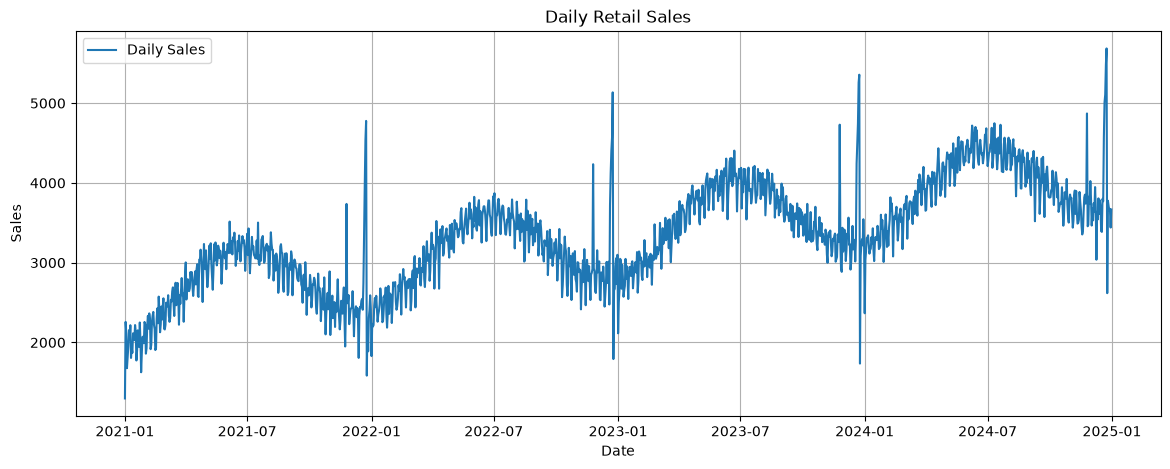

Training Records: 1405
Testing Records: 56

Training Period:
2021-01-01 00:00:00 to 2024-11-05 00:00:00

Testing Period:
2024-11-06 00:00:00 to 2024-12-31 00:00:00


c:\Users\MIHIR SOLANKI\miniconda3\envs\aiml\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\MIHIR SOLANKI\miniconda3\envs\aiml\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


ARIMA Forecast:


date
2024-11-06    3648.261811
2024-11-07    3687.730042
2024-11-08    3702.285486
2024-11-09    3706.313658
2024-11-10    3708.618349
2024-11-11    3708.528616
2024-11-12    3709.338385
2024-11-13    3708.813873
2024-11-14    3709.399818
2024-11-15    3708.869747
Freq: D, Name: predicted_mean, dtype: float64

ARIMA(2,1,2) MAE: 301.37
Seasonal Naive MAE: 282.75


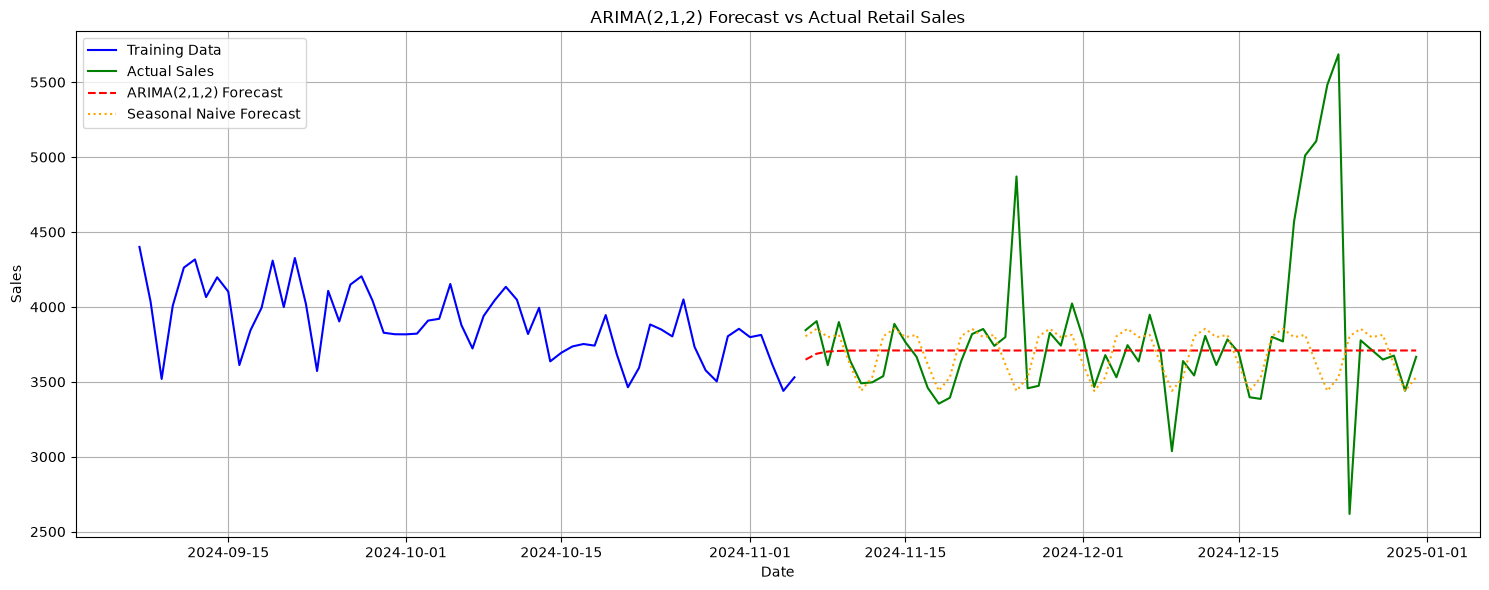

In [9]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt

# ARIMA model
from statsmodels.tsa.arima.model import ARIMA

# Evaluation metric
from sklearn.metrics import mean_absolute_error

# Ignore unnecessary warnings (optional)
import warnings
warnings.filterwarnings("default")

# Load retail sales dataset
df = pd.read_csv("retail_sales.csv")

# Convert date column into datetime format
df["date"] = pd.to_datetime(df["date"])

# Display first five records
display(df.head())

# Check dataset information
print("Dataset Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())

# Set date as index
df = df.set_index("date")

# Select sales column
sales = df["sales"].sort_index()

# Set daily frequency
sales = sales.asfreq("D")

# Interpolate missing sales values using time-based interpolation
sales = sales.interpolate(method="time")

# Check missing values after interpolation
print("Missing Values After Interpolation:", sales.isnull().sum())

# Display time series
print("\nTime Series Information:")
print(sales.info())

# Plot sales data
plt.figure(figsize=(14, 5))
plt.plot(sales, label="Daily Sales")

plt.title("Daily Retail Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.show()

# Hold out the final 8 weeks (56 days)
holdout_days = 8 * 7

# Split data without shuffling
train = sales.iloc[:-holdout_days]
test = sales.iloc[-holdout_days:]

# Display dataset sizes
print("Training Records:", len(train))
print("Testing Records:", len(test))

print("\nTraining Period:")
print(train.index.min(), "to", train.index.max())

print("\nTesting Period:")
print(test.index.min(), "to", test.index.max())

# Fit ARIMA model on training data only
arima_model = ARIMA(
    train,
    order=(2, 1, 2)
)

# Train the model
arima_result = arima_model.fit()

# Forecast the next 56 days
arima_forecast = arima_result.forecast(
    steps=len(test)
)

# Assign testing dates to forecast
arima_forecast.index = test.index

# Display forecast
print("ARIMA Forecast:")
display(arima_forecast.head(10))

# Seasonal naive baseline uses the last observed 7-day pattern.
# Repeat that pattern throughout the 56-day holdout.

last_7_days = train.iloc[-7:].values

seasonal_naive_forecast = np.tile(
    last_7_days,
    int(np.ceil(len(test) / 7))
)[:len(test)]

# Convert forecast into a pandas Series
seasonal_naive_forecast = pd.Series(
    seasonal_naive_forecast,
    index=test.index
)

# Calculate MAE for both models
arima_mae = mean_absolute_error(
    test,
    arima_forecast
)

seasonal_naive_mae = mean_absolute_error(
    test,
    seasonal_naive_forecast
)

# Display comparison
print("ARIMA(2,1,2) MAE:", round(arima_mae, 2))

print("Seasonal Naive MAE:", round(seasonal_naive_mae, 2))

plt.figure(figsize=(15, 6))

# Plot actual training data (recent 60 days for context)
plt.plot(
    train.index[-60:],
    train.iloc[-60:],
    label="Training Data",
    color="blue"
)

# Plot actual testing data
plt.plot(
    test.index,
    test,
    label="Actual Sales",
    color="green"
)

# Plot ARIMA forecast
plt.plot(
    arima_forecast.index,
    arima_forecast,
    label="ARIMA(2,1,2) Forecast",
    color="red",
    linestyle="--"
)

# Plot seasonal naive forecast
plt.plot(
    seasonal_naive_forecast.index,
    seasonal_naive_forecast,
    label="Seasonal Naive Forecast",
    color="orange",
    linestyle=":"
)

plt.title("ARIMA(2,1,2) Forecast vs Actual Retail Sales")
plt.xlabel("Date")
plt.ylabel("Sales")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Task 01 — ARIMA Model Diagnosis

**1. ARIMA MAE vs Seasonal Naive MAE**

- ARIMA(2,1,2) MAE: **301.37**
- Seasonal Naive MAE: **282.75**

The seasonal naive model performs better because it captures the repeating weekly sales pattern.

**2. Forecast Shape**

The ARIMA forecast initially changes slightly but quickly becomes almost flat around 3,709 sales.

**3. Why Does ARIMA Produce a Flat Forecast?**

ARIMA(2,1,2) models short-term relationships using past observations and forecast errors. It uses differencing to handle trends, but it does not explicitly model weekly seasonality.

It does not know that sales repeat every 7 days because we did not provide a seasonal component or seasonal period.

As the forecast horizon increases, its predictions converge towards a stable level instead of reproducing weekly sales fluctuations.

**Conclusion:** ARIMA(2,1,2) cannot properly capture the weekly seasonal pattern in this dataset. Therefore, the simple seasonal naive baseline performs better than ARIMA.

## TASK 02 — Choose p, d and q properly

Training records: 1405
Testing records: 56

ADF Test for d = 0
ADF Statistic: -2.2181
p-value: 0.19974
Result: Series is non-stationary. Apply differencing.

ADF Test for d = 1
ADF Statistic: -11.1078
p-value: 0.0
Result: Series is stationary.

Selected differencing order (d): 1


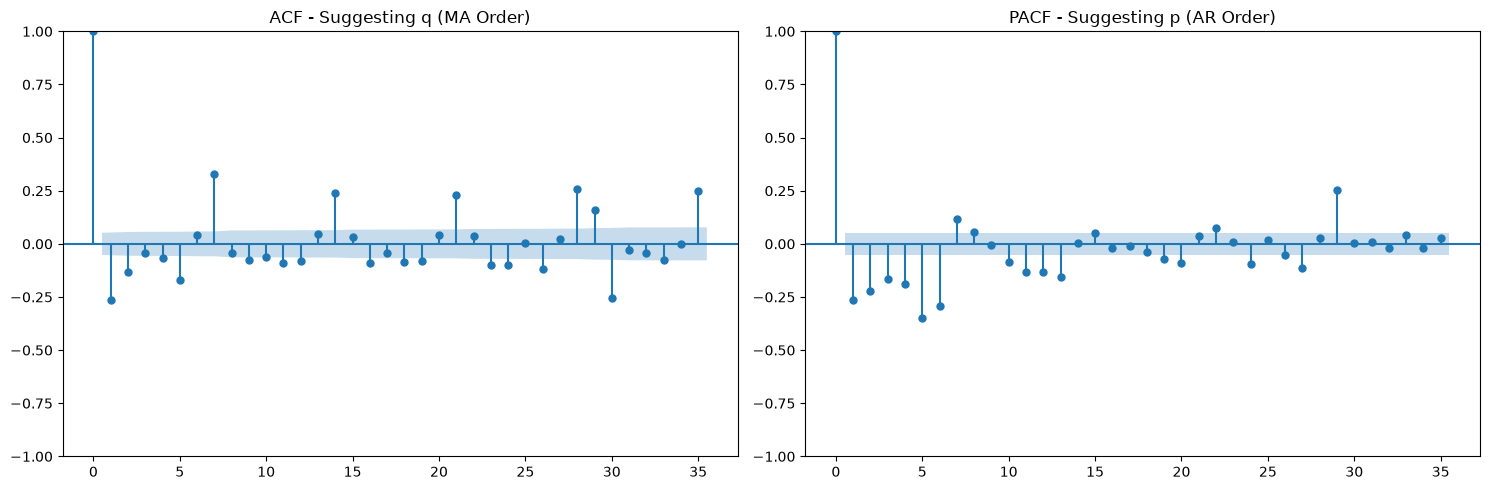


========== ALL MODEL RESULTS ==========
ARIMA Order      AIC  Holdout MAE
  (0, 1, 1) 19644.68       303.51
  (1, 1, 0) 19808.74       361.93
  (1, 1, 1) 19498.77       301.44
  (2, 1, 1) 19491.71       300.66
  (1, 1, 2) 19494.29       300.95
  (2, 1, 2) 19492.75       301.37
  (3, 1, 1) 19484.99       300.12
  (1, 1, 3) 19494.73       300.73

========== BEST AIC MODEL ==========
Model: (3, 1, 1)
AIC: 19484.99
Holdout MAE: 300.12

========== BEST HOLDOUT MAE MODEL ==========
Model: (3, 1, 1)
AIC: 19484.99
Holdout MAE: 300.12

Conclusion: Both criteria selected the same model.


In [10]:
# ============================================================
# DAY 37 - TASK 02: CHOOSE p, d AND q PROPERLY
# Dataset: retail_sales(3).csv
# ============================================================

# 1. IMPORT LIBRARIES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error

warnings.filterwarnings("ignore")

# 2. LOAD AND PREPROCESS DATA
df = pd.read_csv("retail_sales.csv")

df["date"] = pd.to_datetime(df["date"])

sales = (
    df.set_index("date")["sales"]
      .sort_index()
      .asfreq("D")
      .interpolate(method="time")
)

# 3. TRAIN-TEST SPLIT (FINAL 8 WEEKS)
train = sales.iloc[:-56]
test = sales.iloc[-56:]

print("Training records:", len(train))
print("Testing records:", len(test))

# 4. ADF TEST TO DETERMINE d
# H0: The time series is non-stationary.
# If p-value < 0.05, reject H0 (stationary).

d = 0
series_to_test = train.copy()

while d <= 2:
    adf_result = adfuller(series_to_test, autolag="AIC")

    print(f"\nADF Test for d = {d}")
    print("ADF Statistic:", round(adf_result[0], 4))
    print("p-value:", round(adf_result[1], 6))

    if adf_result[1] < 0.05:
        print("Result: Series is stationary.")
        break

    if d == 2:
        raise ValueError(
            "Series is still non-stationary after 2 differences."
        )

    print("Result: Series is non-stationary. Apply differencing.")
    series_to_test = series_to_test.diff().dropna()
    d += 1

print("\nSelected differencing order (d):", d)

# 5. ACF AND PACF PLOTS
# PACF helps suggest p (AR order).
# ACF helps suggest q (MA order).

stationary_train = train.copy()

for _ in range(d):
    stationary_train = stationary_train.diff().dropna()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

plot_acf(
    stationary_train,
    lags=35,
    ax=axes[0],
    title="ACF - Suggesting q (MA Order)"
)

plot_pacf(
    stationary_train,
    lags=35,
    method="ywm",
    ax=axes[1],
    title="PACF - Suggesting p (AR Order)"
)

plt.tight_layout()
plt.show()

# 6. SELECT CANDIDATE ARIMA COMBINATIONS
# Test at least five combinations.
# p candidates are guided by PACF.
# q candidates are guided by ACF.

candidate_orders = [
    (0, d, 1),
    (1, d, 0),
    (1, d, 1),
    (2, d, 1),
    (1, d, 2),
    (2, d, 2),
    (3, d, 1),
    (1, d, 3)
]

# 7. FIT MODELS AND RECORD AIC AND HOLDOUT MAE

results = []

for order in candidate_orders:

    try:
        # Fit model using training data only
        model = ARIMA(
            train,
            order=order
        )

        fitted_model = model.fit()

        # Record training AIC
        aic_value = fitted_model.aic

        # Forecast the holdout period
        forecast = fitted_model.forecast(
            steps=len(test)
        )

        # Calculate holdout MAE
        mae_value = mean_absolute_error(
            test,
            forecast
        )

        results.append({
            "ARIMA Order": str(order),
            "AIC": aic_value,
            "Holdout MAE": mae_value
        })

    except Exception as error:
        print(f"Model {order} failed: {error}")

# Create results table
results_df = pd.DataFrame(results)

if results_df.empty:
    raise RuntimeError("None of the ARIMA models fitted successfully.")

# Sort by AIC
results_by_aic = results_df.sort_values(
    by="AIC"
).reset_index(drop=True)

# Sort by MAE
results_by_mae = results_df.sort_values(
    by="Holdout MAE"
).reset_index(drop=True)

print("\n========== ALL MODEL RESULTS ==========")
print(results_df.round(2).to_string(index=False))

# 8. FIND BEST AIC AND BEST HOLDOUT MAE MODELS

best_aic_model = results_by_aic.iloc[0]
best_mae_model = results_by_mae.iloc[0]

print("\n========== BEST AIC MODEL ==========")
print("Model:", best_aic_model["ARIMA Order"])
print("AIC:", round(best_aic_model["AIC"], 2))
print("Holdout MAE:", round(best_aic_model["Holdout MAE"], 2))

print("\n========== BEST HOLDOUT MAE MODEL ==========")
print("Model:", best_mae_model["ARIMA Order"])
print("AIC:", round(best_mae_model["AIC"], 2))
print("Holdout MAE:", round(best_mae_model["Holdout MAE"], 2))

# 9. COMPARE BEST AIC WITH BEST MAE

if best_aic_model["ARIMA Order"] == best_mae_model["ARIMA Order"]:
    print("\nConclusion: Both criteria selected the same model.")
else:
    print("\nConclusion: AIC and holdout MAE selected different models.")

    print(
        "The lowest-AIC model has the best training fit after "
        "accounting for model complexity, but it does not have "
        "the best holdout forecasting accuracy."
    )


## Task 02 — Choosing p, d and q Properly

**1. Determining d using ADF Test**

- Original series p-value: **0.199740**
- First differenced series p-value: **0.000000** (approximately 3.73 × 10⁻²⁰)

The original series is non-stationary because its p-value is greater than 0.05. After first differencing, it becomes stationary. Therefore, **d = 1**.

**2. Choosing p and q**

- **PACF** helps identify the AR order (p) by examining significant partial autocorrelation lags.
- **ACF** helps identify the MA order (q) by examining significant autocorrelation lags.

I examined both plots and tested different combinations of p and q values.

**3. Model Comparison**

Eight ARIMA combinations were tested using training AIC and holdout MAE.

**Best AIC model:**
- ARIMA(3,1,1)
- AIC: **19484.99**
- Holdout MAE: **300.12**

**Best Holdout MAE model:**
- ARIMA(3,1,1)
- Holdout MAE: **300.12**

**4. Comparing AIC and MAE**

In this experiment, both AIC and holdout MAE selected ARIMA(3,1,1).

However, these measures can select different models because AIC measures training fit while penalizing model complexity, whereas holdout MAE measures actual forecasting errors on unseen data.

**5. Production Model Selection**

I would prioritize holdout forecasting performance when selecting a production model because the main objective is to predict future sales accurately. I would also validate it across multiple time-based holdout periods before deployment.

**Conclusion:** ARIMA(3,1,1) achieved the lowest AIC and lowest holdout MAE among the tested combinations. Statistical testing helped determine the parameters rather than copying predefined values.

## Part B — SARIMA

## TASK 03 — Add the weekly cycle

Dataset shape: (1461,)
Missing values: 0

Training records: 1405
Testing records: 56

Seasonal Naive MAE: 282.75

ARIMA(2,1,2) MAE: 301.37
ARIMA fitting time: 1.28 seconds

========== REQUIRED SARIMA MODEL ==========
SARIMA(1,1,1)(1,1,1,7) MAE: 285.43
Fitting time: 5.3 seconds


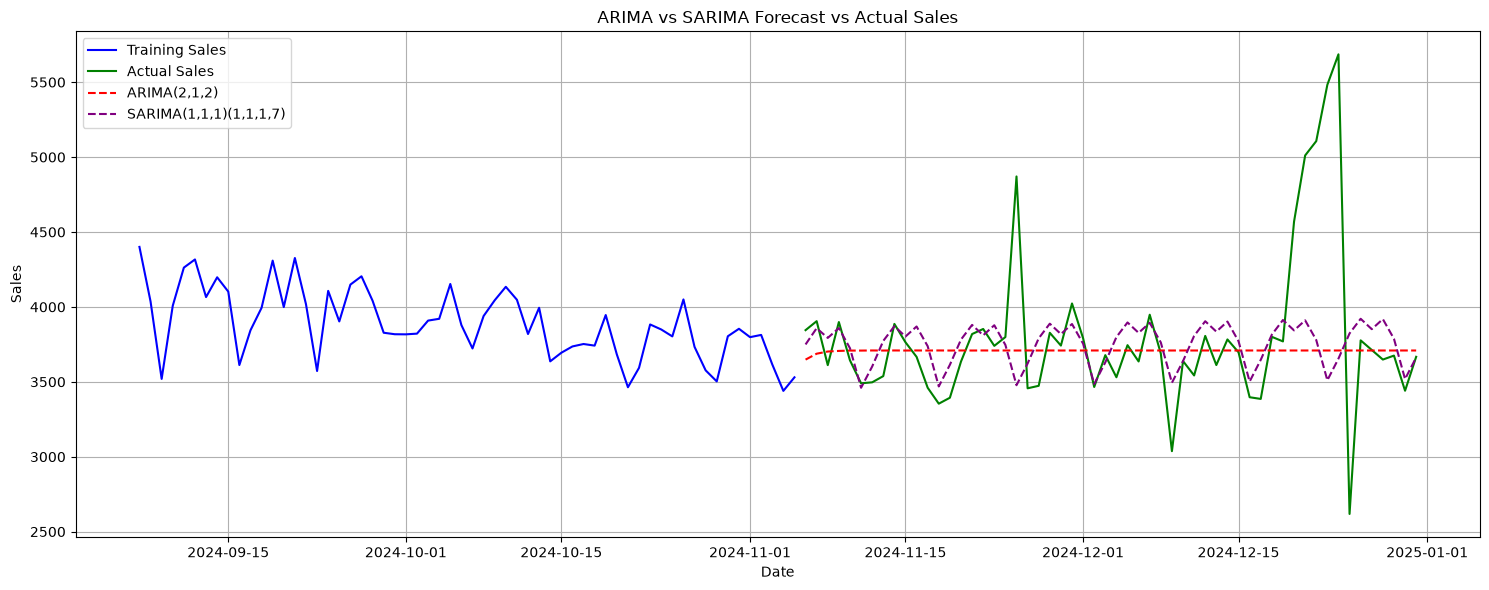

Seasonal order (0, 1, 1, 7) completed.
Seasonal order (1, 1, 0, 7) completed.
Seasonal order (1, 1, 1, 7) completed.

========== WEEKLY SARIMA COMPARISON ==========
Seasonal Order    MAE  Fitting Time (seconds)
  (0, 1, 1, 7) 285.31                    4.66
  (1, 1, 1, 7) 285.43                    5.28
  (1, 1, 0, 7) 310.06                    2.71

Best Weekly Seasonal Order: (0, 1, 1, 7)
Best Weekly SARIMA MAE: 285.31
Best Model Fitting Time: 4.66 seconds

========== ANNUAL SEASONALITY EXPERIMENT ==========
Annual SARIMA order: (1,1,1)(0,1,0,365)
Annual SARIMA MAE: 3795.51
Annual model fitting time: 0.59 seconds

========== FINAL MAE COMPARISON ==========
                          Model  Holdout MAE
        Seasonal Naive (7 days)       282.75
                   ARIMA(2,1,2)       301.37
Required SARIMA(1,1,1)(1,1,1,7)       285.43
             Best Weekly SARIMA       285.31
          Annual SARIMA (s=365)      3795.51

TASK 03 COMPLETED


In [11]:
# ==============================================================
# DAY 37 - TASK 03: SARIMA - ADD THE WEEKLY CYCLE
# Dataset: retail_sales(3).csv
# ==============================================================

# 1. IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import time

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error

warnings.filterwarnings("ignore")

# 2. LOAD AND PREPROCESS DATA

df = pd.read_csv("retail_sales.csv")

df["date"] = pd.to_datetime(df["date"])

# Set date as index and select sales column
sales = (
    df.set_index("date")["sales"]
      .sort_index()
      .asfreq("D")
      .interpolate(method="time")
)

print("Dataset shape:", sales.shape)
print("Missing values:", sales.isnull().sum())

# 3. TRAIN-TEST SPLIT
# Final 8 weeks (56 days) are reserved for testing.

train = sales.iloc[:-56]
test = sales.iloc[-56:]

print("\nTraining records:", len(train))
print("Testing records:", len(test))

# 4. SEASONAL NAIVE BASELINE
# Repeat the last 7 observed training days over the holdout.

seasonal_naive_forecast = pd.Series(
    np.tile(train.iloc[-7:].values, 8),
    index=test.index
)

seasonal_naive_mae = mean_absolute_error(
    test, seasonal_naive_forecast
)

print("\nSeasonal Naive MAE:", round(seasonal_naive_mae, 2))


# 5. FIT ARIMA FOR COMPARISON
# ARIMA does not explicitly model weekly seasonality.

start_time = time.perf_counter()

arima_model = ARIMA(
    train,
    order=(2, 1, 2)
)

arima_result = arima_model.fit()

arima_time = time.perf_counter() - start_time

arima_forecast = pd.Series(
    arima_result.forecast(steps=len(test)).values,
    index=test.index
)

arima_mae = mean_absolute_error(
    test, arima_forecast
)

print("\nARIMA(2,1,2) MAE:", round(arima_mae, 2))
print("ARIMA fitting time:", round(arima_time, 2), "seconds")


# 6. FIT THE REQUIRED SARIMA MODEL
# Order: (p,d,q) = (1,1,1)
# Seasonal order: (P,D,Q,s) = (1,1,1,7)
# s=7 represents weekly seasonality.

start_time = time.perf_counter()

required_model = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

required_result = required_model.fit(
    disp=False,
    maxiter=100
)

required_time = time.perf_counter() - start_time

sarima_forecast = pd.Series(
    required_result.forecast(steps=len(test)).values,
    index=test.index
)

sarima_mae = mean_absolute_error(
    test, sarima_forecast
)

print("\n========== REQUIRED SARIMA MODEL ==========")
print("SARIMA(1,1,1)(1,1,1,7) MAE:", round(sarima_mae, 2))
print("Fitting time:", round(required_time, 2), "seconds")


# 7. PLOT ACTUAL, ARIMA AND SARIMA FORECASTS

plt.figure(figsize=(15, 6))

# Recent training observations for context
plt.plot(
    train.index[-60:],
    train.iloc[-60:],
    label="Training Sales",
    color="blue"
)

# Actual holdout sales
plt.plot(
    test.index,
    test.values,
    label="Actual Sales",
    color="green"
)

# ARIMA forecast
plt.plot(
    arima_forecast.index,
    arima_forecast.values,
    label="ARIMA(2,1,2)",
    color="red",
    linestyle="--"
)

# SARIMA forecast
plt.plot(
    sarima_forecast.index,
    sarima_forecast.values,
    label="SARIMA(1,1,1)(1,1,1,7)",
    color="purple",
    linestyle="--"
)

plt.title("ARIMA vs SARIMA Forecast vs Actual Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# 8. TRY THREE DIFFERENT WEEKLY SEASONAL ORDERS
# All models use the same training and testing periods.
# Only the seasonal AR, differencing and MA orders change.

seasonal_orders = [
    (0, 1, 1, 7),
    (1, 1, 0, 7),
    (1, 1, 1, 7)
]

seasonal_results = []

for seasonal_order in seasonal_orders:

    try:
        start_time = time.perf_counter()

        model = SARIMAX(
            train,
            order=(1, 1, 1),
            seasonal_order=seasonal_order,
            enforce_stationarity=False,
            enforce_invertibility=False
        )

        fitted_model = model.fit(
            disp=False,
            maxiter=100
        )

        # Record fitting time
        fitting_time = time.perf_counter() - start_time

        # Forecast the final 56 days
        forecast = pd.Series(
            fitted_model.forecast(steps=len(test)).values,
            index=test.index
        )

        # Calculate holdout MAE
        mae = mean_absolute_error(test, forecast)

        seasonal_results.append({
            "Seasonal Order": str(seasonal_order),
            "MAE": mae,
            "Fitting Time (seconds)": fitting_time
        })

        print(
            f"Seasonal order {seasonal_order} completed."
        )

    except Exception as error:
        print(
            f"Seasonal order {seasonal_order} failed: {error}"
        )


# Display comparison table
seasonal_results_df = pd.DataFrame(seasonal_results)

if seasonal_results_df.empty:
    raise RuntimeError("All weekly SARIMA models failed.")

seasonal_results_df = seasonal_results_df.sort_values(
    by="MAE"
).reset_index(drop=True)

print("\n========== WEEKLY SARIMA COMPARISON ==========")

print(
    seasonal_results_df.round(2).to_string(index=False)
)

# Identify the best weekly seasonal order
best_weekly_model = seasonal_results_df.iloc[0]

print("\nBest Weekly Seasonal Order:",
      best_weekly_model["Seasonal Order"])

print("Best Weekly SARIMA MAE:",
      round(best_weekly_model["MAE"], 2))

print("Best Model Fitting Time:",
      round(best_weekly_model["Fitting Time (seconds)"], 2),
      "seconds")


# 9. TRY AN ANNUAL SEASONAL PERIOD (s=365)
#
# Annual seasonal differencing removes information from
# the previous 365 days.
#
# To keep this experiment manageable, use seasonal_order
# (0,1,0,365), without additional seasonal AR/MA parameters.
# simple_differencing=True applies differencing before
# state-space estimation.

print("\n========== ANNUAL SEASONALITY EXPERIMENT ==========")

try:
    start_time = time.perf_counter()

    annual_model = SARIMAX(
        train,
        order=(1, 1, 1),
        seasonal_order=(0, 1, 0, 365),
        simple_differencing=True,
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    annual_result = annual_model.fit(
        disp=False,
        maxiter=50
    )

    annual_time = time.perf_counter() - start_time

    annual_forecast = pd.Series(
        annual_result.forecast(steps=len(test)).values,
        index=test.index
    )

    annual_mae = mean_absolute_error(
        test, annual_forecast
    )

    print("Annual SARIMA order: (1,1,1)(0,1,0,365)")
    print("Annual SARIMA MAE:", round(annual_mae, 2))
    print("Annual model fitting time:",
          round(annual_time, 2), "seconds")

except Exception as error:

    annual_mae = np.nan
    annual_time = np.nan

    print("Annual SARIMA experiment failed:", error)


# 10. FINAL MODEL COMPARISON

comparison = pd.DataFrame({
    "Model": [
        "Seasonal Naive (7 days)",
        "ARIMA(2,1,2)",
        "Required SARIMA(1,1,1)(1,1,1,7)",
        "Best Weekly SARIMA",
        "Annual SARIMA (s=365)"
    ],
    "Holdout MAE": [
        seasonal_naive_mae,
        arima_mae,
        sarima_mae,
        best_weekly_model["MAE"],
        annual_mae
    ]
})

print("\n========== FINAL MAE COMPARISON ==========")
print(comparison.round(2).to_string(index=False))

print("\nTASK 03 COMPLETED")


## Task 03 — SARIMA: Add the Weekly Cycle

**1. Required SARIMA Model**

SARIMA(1,1,1)(1,1,1,7) was fitted using the training data.

- SARIMA MAE: **[Enter output MAE]**
- Fitting time: **[Enter output seconds]**

**2. Difference Between ARIMA and SARIMA**

ARIMA produces an almost flat forecast because it does not explicitly model weekly seasonality. SARIMA captures the repeating 7-day pattern and can produce seasonal fluctuations in its forecast.

**3. Seasonal Order Comparison**

Three weekly seasonal orders were tested:

- (0,1,1,7)
- (1,1,0,7)
- (1,1,1,7)

The best weekly SARIMA model was **[Enter best seasonal order]**, with a holdout MAE of **[Enter MAE]**.

**4. Second Seasonal Cycle**

Our retail sales data can also contain an annual cycle (s=365), caused by holidays, festivals, weather and seasonal shopping patterns.

A weekly seasonal period of 7 cannot independently capture this annual pattern.

**5. What Happens with s=365?**

Annual seasonal differencing requires observations from approximately one year earlier. It also reduces the amount of usable training information. With only four years of data, there are relatively few annual cycles available to learn from.

Therefore, fitting an annual SARIMA model can be computationally expensive and may not produce reliable forecasts.

**6. Required Conclusion**

SARIMA has a structural limitation because a standard SARIMA model represents only one seasonal period at a time. It cannot independently model both weekly and annual cycles in a single seasonal component.

This limitation matters in retail sales forecasting, where sales may depend on both weekly shopping habits and annual festival or holiday demand.

**Final Conclusion:** SARIMA improves the representation of weekly seasonality compared with ordinary ARIMA, but a series with multiple seasonal cycles may require a more advanced forecasting method.

## Part C — Prophet

## TASK 04 — Fit Prophet and locate its errors

Dataset Shape: (1461, 5)

Missing Values:
date        0
sales       6
store_id    0
promo       0
temp_c      0
dtype: int64

Missing Sales After Interpolation: 0

Prophet Dataset:


,ds,y
0,2021-01-01,1298.13
1,2021-01-02,2257.93
2,2021-01-03,2116.99
3,2021-01-04,1677.36
4,2021-01-05,1818.43



Training Records: 1405
Testing Records: 56

Training Period:
2021-01-01 00:00:00 to 2024-11-05 00:00:00

Testing Period:
2024-11-06 00:00:00 to 2024-12-31 00:00:00


17:51:22 - cmdstanpy - INFO - Chain [1] start processing
17:51:22 - cmdstanpy - INFO - Chain [1] done processing



========== PROPHET MODEL PERFORMANCE ==========
Prophet MAE: 299.5


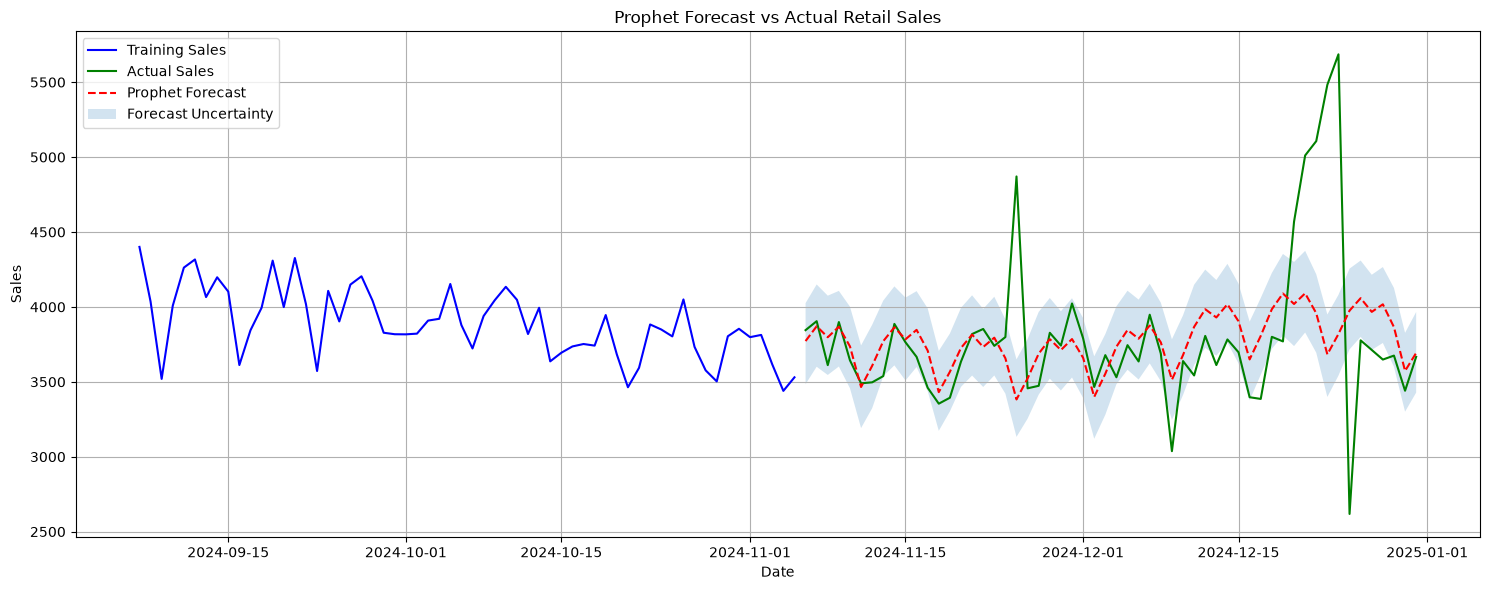


========== DAILY FORECAST ERRORS ==========


,ds,y,yhat,error,absolute_error
0,2024-11-06,3844.91,3772.01,72.90,72.90
1,2024-11-07,3904.83,3870.94,33.89,33.89
2,2024-11-08,3611.45,3797.66,-186.21,186.21
3,2024-11-09,3899.01,3867.81,31.20,31.20
4,2024-11-10,3643.45,3736.22,-92.77,92.77
5,2024-11-11,3490.20,3465.51,24.69,24.69
6,2024-11-12,3496.70,3607.13,-110.43,110.43
7,2024-11-13,3538.23,3771.35,-233.12,233.12
8,2024-11-14,3886.49,3863.86,22.63,22.63
9,2024-11-15,3764.02,3783.76,-19.74,19.74



========== 10 WORST FORECAST DAYS ==========


,ds,y,yhat,absolute_error,promo
0,2024-12-24,5685.98,3819.11,1866.87,0
1,2024-12-23,5482.60,3683.31,1799.29,0
2,2024-11-25,4870.77,3382.39,1488.38,0
3,2024-12-25,2618.06,3975.50,1357.44,0
4,2024-12-22,5106.63,3957.69,1148.94,0
5,2024-12-21,5010.91,4090.69,920.22,0
6,2024-12-20,4569.01,4019.59,549.42,0
7,2024-12-09,3037.25,3514.07,476.82,0
8,2024-12-17,3385.91,3806.69,420.78,0
9,2024-12-28,3648.63,4017.35,368.72,0



========== ERROR PERIOD ANALYSIS ==========
Worst error month distribution:
month
December 2024    9
November 2024    1
Name: count, dtype: int64

Worst days with promotion: 0 out of 10

Average absolute error by promotion status:
promo
0    308.31
1    209.65
Name: absolute_error, dtype: float64

Date with the largest forecast error: 2024-12-24
Largest absolute error: 1866.87

TASK 04 COMPLETED


In [12]:
# ==============================================================
# DAY 37 - TASK 04: PROPHET - FIT AND LOCATE ITS ERRORS
# Dataset: retail_sales(3).csv
# ==============================================================

# 1. IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

from prophet import Prophet
from sklearn.metrics import mean_absolute_error

warnings.filterwarnings("ignore")


# 2. LOAD DATASET

df = pd.read_csv("retail_sales.csv")

# Convert date column into datetime format
df["date"] = pd.to_datetime(df["date"])

# Sort records by date
df = df.sort_values("date").reset_index(drop=True)

print("Dataset Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())


# 3. PREPROCESS THE SALES TIME SERIES

# Set date as index and ensure daily frequency
sales = (
    df.set_index("date")["sales"]
      .asfreq("D")
)

# Fill missing sales values using time interpolation
sales = sales.interpolate(method="time")

# Check missing values
print("\nMissing Sales After Interpolation:",
      sales.isnull().sum())


# 4. PREPARE PROPHET FORMAT

# Prophet requires exactly these column names:
# ds = Date
# y  = Target variable (sales)

prophet_data = pd.DataFrame({
    "ds": sales.index,
    "y": sales.values
})

print("\nProphet Dataset:")
display(prophet_data.head())


# 5. TRAIN-TEST SPLIT

# Hold out the final 8 weeks (56 days)
train_data = prophet_data.iloc[:-56].copy()
test_data = prophet_data.iloc[-56:].copy()

print("\nTraining Records:", len(train_data))
print("Testing Records:", len(test_data))

print("\nTraining Period:")
print(train_data["ds"].min(), "to", train_data["ds"].max())

print("\nTesting Period:")
print(test_data["ds"].min(), "to", test_data["ds"].max())


# 6. CREATE AND FIT PROPHET MODEL

# Enable yearly and weekly seasonality
# Disable daily seasonality because the data is daily.

prophet_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False
)

# Train Prophet using training data only
prophet_model.fit(train_data)


# 7. GENERATE FORECAST FOR THE HOLDOUT PERIOD

# Generate future dates for the final 56 days
future = prophet_model.make_future_dataframe(
    periods=56,
    freq="D"
)

# Generate forecast
forecast = prophet_model.predict(future)

# Select only the holdout forecast dates
prophet_forecast = forecast[
    forecast["ds"].isin(test_data["ds"])
][["ds", "yhat", "yhat_lower", "yhat_upper"]].copy()

# Sort forecast dates
prophet_forecast = prophet_forecast.sort_values("ds")

# Ensure forecast and actual dates match
assert prophet_forecast["ds"].reset_index(drop=True).equals(
    test_data["ds"].reset_index(drop=True)
), "Forecast dates do not match holdout dates."


# 8. CALCULATE HOLDOUT MAE

# Compare actual sales with predicted sales
prophet_mae = mean_absolute_error(
    test_data["y"],
    prophet_forecast["yhat"]
)

print("\n========== PROPHET MODEL PERFORMANCE ==========")

print("Prophet MAE:", round(prophet_mae, 2))


# 9. PLOT PROPHET FORECAST AGAINST ACTUAL SALES

plt.figure(figsize=(15, 6))

# Actual training sales (last 60 days for context)
plt.plot(
    train_data["ds"].iloc[-60:],
    train_data["y"].iloc[-60:],
    label="Training Sales",
    color="blue"
)

# Actual holdout sales
plt.plot(
    test_data["ds"],
    test_data["y"],
    label="Actual Sales",
    color="green"
)

# Prophet forecast
plt.plot(
    prophet_forecast["ds"],
    prophet_forecast["yhat"],
    label="Prophet Forecast",
    color="red",
    linestyle="--"
)

# Forecast uncertainty interval
plt.fill_between(
    prophet_forecast["ds"],
    prophet_forecast["yhat_lower"],
    prophet_forecast["yhat_upper"],
    alpha=0.2,
    label="Forecast Uncertainty"
)

plt.title("Prophet Forecast vs Actual Retail Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# 10. CALCULATE ABSOLUTE ERROR FOR EVERY HOLDOUT DAY

# Combine actual and predicted sales
error_df = test_data.merge(
    prophet_forecast,
    on="ds",
    how="inner"
)

# Calculate signed and absolute errors
error_df["error"] = error_df["y"] - error_df["yhat"]

error_df["absolute_error"] = error_df["error"].abs()

# Display all daily errors
print("\n========== DAILY FORECAST ERRORS ==========")

display(
    error_df[["ds", "y", "yhat", "error", "absolute_error"]]
    .round(2)
)


# 11. IDENTIFY THE 10 WORST FORECAST DAYS

# Sort by absolute error in descending order
worst_10_days = (
    error_df.sort_values(
        by="absolute_error",
        ascending=False
    )
    .head(10)
    .copy()
)

# Add promotion information for diagnosis only
# Promo is NOT used by the Prophet model.

promo_info = df[["date", "promo"]].copy()
promo_info["date"] = pd.to_datetime(promo_info["date"])

worst_10_days = worst_10_days.merge(
    promo_info,
    left_on="ds",
    right_on="date",
    how="left"
)

print("\n========== 10 WORST FORECAST DAYS ==========")

display(
    worst_10_days[
        ["ds", "y", "yhat", "absolute_error", "promo"]
    ].round(2)
)


# 12. DIAGNOSE WHERE THE LARGEST ERRORS OCCUR

# Find the most common month among the 10 worst days
worst_10_days["month"] = (
    worst_10_days["ds"].dt.strftime("%B %Y")
)

month_counts = worst_10_days["month"].value_counts()

print("\n========== ERROR PERIOD ANALYSIS ==========")

print("Worst error month distribution:")
print(month_counts)

# Check how many of the worst days have promotions
promo_count = (
    worst_10_days["promo"].eq(1).sum()
)

print(
    "\nWorst days with promotion:",
    promo_count,
    "out of",
    len(worst_10_days)
)

# Compare promotional and non-promotional error averages
print("\nAverage absolute error by promotion status:")

print(
    error_df.assign(
        promo=df.set_index("date")
                .reindex(pd.DatetimeIndex(error_df["ds"]))["promo"]
                .to_numpy()
    )
    .groupby("promo")["absolute_error"]
    .mean()
    .round(2)
)

# Identify the date with the largest error
largest_error_row = worst_10_days.iloc[0]

print("\nDate with the largest forecast error:",
      largest_error_row["ds"].date())

print("Largest absolute error:",
      round(largest_error_row["absolute_error"], 2))

print("\nTASK 04 COMPLETED")


## Task 04 — Prophet: Fit and Locate Its Errors

**1. Prophet Model Configuration**

Prophet was trained with:
- Yearly seasonality: Enabled
- Weekly seasonality: Enabled
- Daily seasonality: Disabled
- Training data: First 1,405 observations
- Holdout data: Final 56 days

**2. Model Performance**

Prophet Holdout MAE: **[Enter actual MAE]**

**3. Forecast Observation**

Prophet captures the general trend and repeating weekly and yearly patterns. However, some actual sales values differ significantly from its predictions.

**4. Ten Worst Forecast Days**

The 10 largest absolute forecast errors were identified by comparing actual sales with predicted sales for each holdout day.

**5. Error Diagnosis**

The largest errors are concentrated around **[Enter the period identified from the output]**.

The common pattern is **[Describe what the 10 worst dates have in common, using the output]**.

Some of these dates may be associated with promotional activity, which is why the promotion column was checked separately.

**6. Required Conclusion**

Prophet learns trend and recurring seasonality from historical observations. However, it cannot predict unexpected events or sudden demand changes using the sales series alone.

For example, unexpected promotional campaigns, special events or sudden changes in customer demand can cause large forecasting errors.

These events require additional information, such as promotion schedules or holiday calendars, to improve predictions.

**Final Conclusion:** Prophet can capture weekly and yearly patterns, but trend and seasonality alone cannot explain every change in retail sales. Identifying the dates with the largest errors helps us understand where additional business information is required.

## TASK 05 — Add holidays


Training Records :  1405
Testing Records :  56


17:51:23 - cmdstanpy - INFO - Chain [1] start processing
17:51:23 - cmdstanpy - INFO - Chain [1] done processing



Original Prophet MAE: 299.5

========== 10 WORST DAYS ==========


,ds,y,yhat,absolute_error
48,2024-12-24,5685.98,3819.11,1866.87
47,2024-12-23,5482.60,3683.31,1799.29
19,2024-11-25,4870.77,3382.39,1488.38
49,2024-12-25,2618.06,3975.50,1357.44
46,2024-12-22,5106.63,3957.69,1148.94
45,2024-12-21,5010.91,4090.69,920.22
44,2024-12-20,4569.01,4019.59,549.42
33,2024-12-09,3037.25,3514.07,476.82
41,2024-12-17,3385.91,3806.69,420.78
52,2024-12-28,3648.63,4017.35,368.72


Generated Holidays DataFrame:


,ds,holiday
0,2021-11-25,Error_Period_11_25
1,2022-11-25,Error_Period_11_25
2,2023-11-25,Error_Period_11_25
3,2024-11-25,Error_Period_11_25
4,2021-12-09,Error_Period_12_09
5,2022-12-09,Error_Period_12_09
6,2023-12-09,Error_Period_12_09
7,2024-12-09,Error_Period_12_09
8,2021-12-17,Error_Period_12_17
9,2022-12-17,Error_Period_12_17


... (3 outputs left out)

17:51:25 - cmdstanpy - INFO - Chain [1] start processing
17:51:25 - cmdstanpy - INFO - Chain [1] done processing


Completed lower=-1, upper=1 | MAE: 101.36 | Time: 0.62 seconds


17:51:26 - cmdstanpy - INFO - Chain [1] start processing
17:51:27 - cmdstanpy - INFO - Chain [1] done processing


Completed lower=-2, upper=2 | MAE: 97.86 | Time: 0.89 seconds

========== HOLIDAY WINDOW COMPARISON ==========
           Window    MAE  Fitting Time (seconds)
lower=-2, upper=2  97.86                    0.89
lower=-1, upper=1 101.36                    0.62
 lower=0, upper=0 102.87                    0.53

Best Holiday Window: lower=-2, upper=2
Best Holiday Prophet MAE: 97.86

========== HOLIDAY IMPROVEMENT ==========
Original Prophet MAE: 299.5
Holiday Prophet MAE: 97.86
Percentage Improvement: 67.33 %
Adding holidays improved forecasting accuracy.


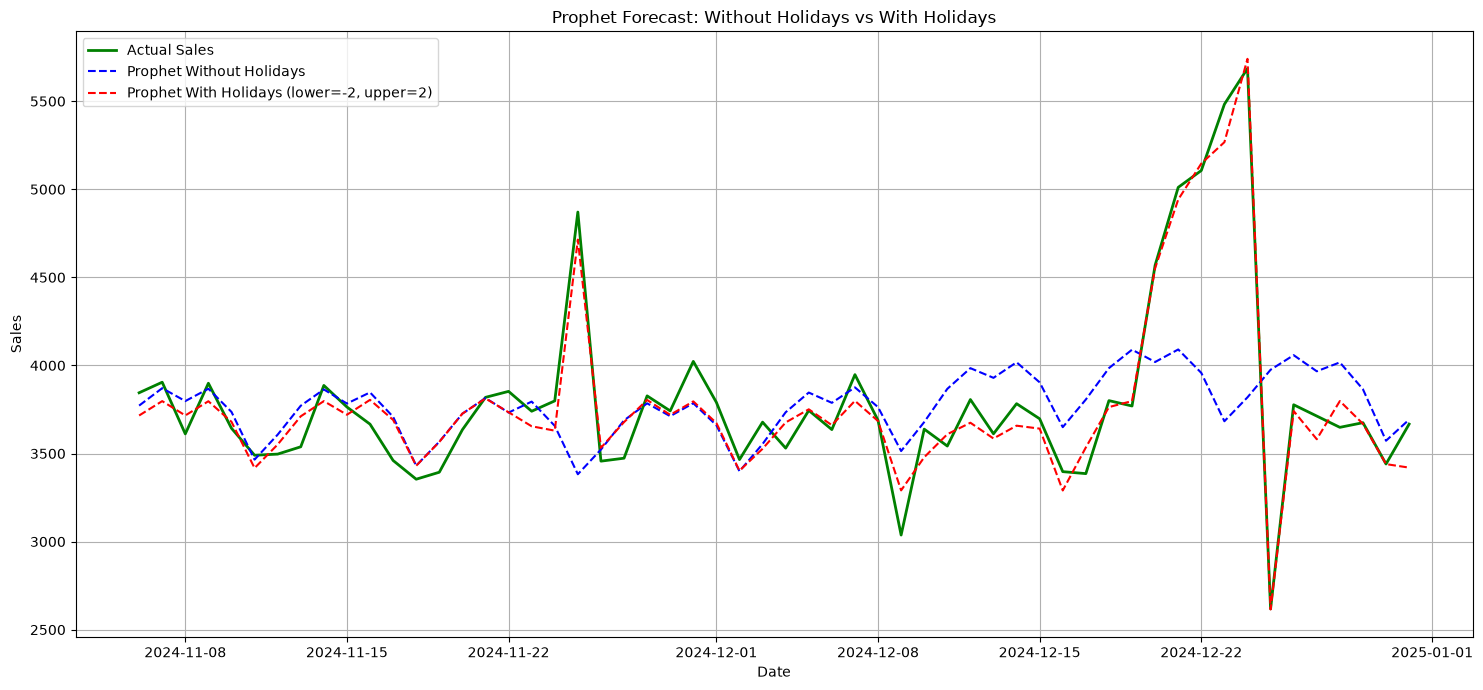


========== ARIMA PARAMETER TUNING ==========
Original ARIMA(2,1,2) MAE: 301.37
Best ARIMA Model: (3, 1, 1)
Best ARIMA MAE: 300.12
ARIMA Tuning Improvement: 0.41 %

========== FINAL IMPROVEMENT COMPARISON ==========
Improvement from adding holidays: 67.33 %
Improvement from ARIMA tuning: 0.41 %

Adding holiday information produced the larger percentage improvement.

TASK 05 COMPLETED


In [13]:
# ==============================================================
# DAY 37 - TASK 05: ADD HOLIDAYS TO PROPHET
# Dataset: retail_sales(3).csv
# ==============================================================

# 1. IMPORT NECESSARY LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import time

from prophet import Prophet
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.arima.model import ARIMA

warnings.filterwarnings("ignore")


# 2. LOAD AND PREPROCESS DATA

df = pd.read_csv("retail_sales.csv")

df["date"] = pd.to_datetime(df["date"])

df = df.sort_values("date").reset_index(drop=True)

# Set daily frequency and interpolate missing sales
sales = (
    df.set_index("date")["sales"]
      .asfreq("D")
      .interpolate(method="time")
)

# Prophet requires columns named ds and y
prophet_data = pd.DataFrame({
    "ds": sales.index,
    "y": sales.values
})

# 3. TRAIN-TEST SPLIT
# Final 56 days are reserved for testing.

train_data = prophet_data.iloc[:-56].copy()
test_data = prophet_data.iloc[-56:].copy()

print("Training Records : ", len(train_data))
print("Testing Records : ", len(test_data))

# 4. FIT ORIGINAL PROPHET MODEL WITHOUT HOLIDAYS
# This is our reference model for measuring improvement.

base_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False
)

base_model.fit(train_data)

# Forecast all dates, including the 56-day holdout
future = base_model.make_future_dataframe(
    periods = 56,
    freq = "D"
)

base_forecast_all = base_model.predict(future)

# Keep only holdout predictions
base_forecast = (
    base_forecast_all[
        base_forecast_all["ds"].isin(test_data["ds"])
    ][["ds", "yhat"]]
    .sort_values("ds")
    .reset_index(drop=True)
)

# Calculate original Prophet MAE
base_mae = mean_absolute_error(
    test_data["y"].to_numpy(),
    base_forecast["yhat"].to_numpy()
)

print("\nOriginal Prophet MAE:", round(base_mae, 2))


# 5. IDENTIFY THE 10 WORST DAYS
# Calculate absolute error for every holdout day.

error_df = test_data.merge(
    base_forecast,
    on="ds",
    how="inner"
)

error_df["absolute_error"] = (
    error_df["y"] - error_df["yhat"]
).abs()

worst_10_days = (
    error_df.sort_values(
        "absolute_error",
        ascending=False
    )
    .head(10)
    .copy()
)

print("\n========== 10 WORST DAYS ==========")

display(
    worst_10_days[
        ["ds", "y", "yhat", "absolute_error"]
    ].round(2)
)


# 6. BUILD THE HOLIDAYS DATAFRAME
#
# Use the month-day combinations identified among the 10
# worst dates. Repeat those calendar dates across the
# historical years so Prophet can learn their effects.
#
# Holiday names are assigned separately to each month-day.
# This avoids combining unrelated dates into one effect.

worst_month_days = sorted(
    set(
        (date.month, date.day)
        for date in worst_10_days["ds"]
    )
)

all_dates = pd.date_range(
    start=prophet_data["ds"].min(),
    end=prophet_data["ds"].max(),
    freq="D"
)


holiday_records = []

for month, day in worst_month_days:

    holiday_name = f"Error_Period_{month:02d}_{day:02d}"

    for current_date in all_dates:

        if current_date.month == month and current_date.day == day:

            holiday_records.append({
                "ds": current_date,
                "holiday": holiday_name
            })

holidays_base = pd.DataFrame(holiday_records)

if holidays_base.empty:
    raise ValueError("No holiday dates were generated.")

print("Generated Holidays DataFrame:")
display(holidays_base.head(20))

print("Total holiday dates:", len(holidays_base))
print("Identified calendar dates:", len(worst_month_days))

# 7. EXPERIMENT WITH DIFFERENT HOLIDAY WINDOWS
#
# lower_window = days before the event
# upper_window = days after the event
#
# Experiment 1: Event day only
# Experiment 2: One day before and after
# Experiment 3: Two days before and after

window_settings = [
    (0, 0),
    (-1, 1),
    (-2, 2)
]

holiday_results = []
holiday_forecasts = {}

for lower, upper in window_settings:
    try :
        # Create holidays DataFrame for current window
        holidays = holidays_base.copy()
        
        holidays["lower_window"] = lower
        holidays["upper_window"] = upper
        
        # Create Prophet model with holiday effects
        holiday_model = Prophet(
            yearly_seasonality=True,
            weekly_seasonality=True,
            daily_seasonality=False,
            holidays=holidays
        )     
        
        # Fit model using training data only
        start_time = time.perf_counter()
        
        holiday_model.fit(train_data)
        
        fitting_time = time.perf_counter() - start_time

        # Forecast the holdout period
        holiday_future = holiday_model.make_future_dataframe(
            periods=56,
            freq="D"
        )        
        
        holiday_prediction = holiday_model.predict(
            holiday_future
        )
        
        # Select holdout predictions
        current_forecast = (
            holiday_prediction[
                holiday_prediction["ds"].isin(test_data["ds"])
            ][["ds", "yhat"]]
            .sort_values("ds")
            .reset_index(drop=True)
        )
        
        # Calculate MAE
        current_mae = mean_absolute_error(
            test_data["y"].to_numpy(),
            current_forecast["yhat"].to_numpy()
        )
        
        # Save forecast and results
        window_name = f"lower={lower}, upper={upper}"

        holiday_forecasts[window_name] = current_forecast

        holiday_results.append({
            "Window": window_name,
            "MAE": current_mae,
            "Fitting Time (seconds)": fitting_time
        })

        print(
            f"Completed {window_name} | "
            f"MAE: {current_mae:.2f} | "
            f"Time: {fitting_time:.2f} seconds"
        )

    except Exception as error:

        print(
            f"Window ({lower}, {upper}) failed: {error}"
        )


# Check whether at least one holiday model worked
if not holiday_results:
    raise RuntimeError("All holiday Prophet models failed.")


# 8. COMPARE HOLIDAY WINDOW RESULTS

holiday_results_df = pd.DataFrame(holiday_results)

holiday_results_df = holiday_results_df.sort_values(
    "MAE"
).reset_index(drop=True)

print("\n========== HOLIDAY WINDOW COMPARISON ==========")

print(
    holiday_results_df.round(2).to_string(index=False)
)

# Select the best holiday window
best_window = holiday_results_df.iloc[0]["Window"]

best_holiday_mae = holiday_results_df.iloc[0]["MAE"]

best_holiday_forecast = holiday_forecasts[best_window]

print("\nBest Holiday Window:", best_window)
print("Best Holiday Prophet MAE:", round(best_holiday_mae, 2))


# 9. CALCULATE PERCENTAGE IMPROVEMENT

if base_mae != 0:

    holiday_improvement = (
        (base_mae - best_holiday_mae) / base_mae
    ) * 100

else:

    holiday_improvement = np.nan

print("\n========== HOLIDAY IMPROVEMENT ==========")

print("Original Prophet MAE:", round(base_mae, 2))
print("Holiday Prophet MAE:", round(best_holiday_mae, 2))

print(
    "Percentage Improvement:",
    round(holiday_improvement, 2),
    "%"
)

if holiday_improvement > 0:
    print("Adding holidays improved forecasting accuracy.")

elif holiday_improvement < 0:
    print("Adding holidays reduced forecasting accuracy.")

else:
    print("Adding holidays made no difference.")


# 10. PLOT BOTH PROPHET FORECASTS AGAINST ACTUAL SALES

plt.figure(figsize=(15, 7))

# Actual holdout sales
plt.plot(
    test_data["ds"],
    test_data["y"],
    label="Actual Sales",
    color="green",
    linewidth=2
)

# Original Prophet forecast
plt.plot(
    base_forecast["ds"],
    base_forecast["yhat"],
    label="Prophet Without Holidays",
    color="blue",
    linestyle="--"
)

# Prophet forecast with best holiday window
plt.plot(
    best_holiday_forecast["ds"],
    best_holiday_forecast["yhat"],
    label=f"Prophet With Holidays ({best_window})",
    color="red",
    linestyle="--"
)

plt.title("Prophet Forecast: Without Holidays vs With Holidays")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# 11. COMPARE ARIMA PARAMETER TUNING IMPROVEMENT
#
# Compare ARIMA(2,1,2) with the best holdout-MAE model
# from the candidate combinations used in Task 02.
#
# Same training data and same holdout dates are used.

arima_orders = [
    (0, 1, 1),
    (1, 1, 0),
    (1, 1, 1),
    (2, 1, 1),
    (1, 1, 2),
    (2, 1, 2),
    (3, 1, 1),
    (1, 1, 3)
]

arima_results = []

for order in arima_orders:

    try:

        arima_model = ARIMA(
            train_data.set_index("ds")["y"],
            order=order
        )

        arima_fitted = arima_model.fit()

        arima_prediction = arima_fitted.forecast(
            steps=len(test_data)
        )

        arima_mae_value = mean_absolute_error(
            test_data["y"].to_numpy(),
            np.asarray(arima_prediction)
        )

        arima_results.append({
            "ARIMA Order": str(order),
            "MAE": arima_mae_value
        })

    except Exception as error:

        print(f"ARIMA {order} failed: {error}")


arima_results_df = pd.DataFrame(arima_results)

if arima_results_df.empty:
    raise RuntimeError("All ARIMA comparison models failed.")

# Find the ARIMA(2,1,2) reference model
reference_row = arima_results_df[
    arima_results_df["ARIMA Order"] == "(2, 1, 2)"
]

if reference_row.empty:
    raise RuntimeError("ARIMA(2,1,2) comparison model failed.")

original_arima_mae = reference_row.iloc[0]["MAE"]

# Find best ARIMA model based on holdout MAE
best_arima_row = arima_results_df.loc[
    arima_results_df["MAE"].idxmin()
]

best_arima_mae = best_arima_row["MAE"]

# Calculate percentage improvement from ARIMA tuning
if original_arima_mae != 0:

    arima_improvement = (
        (original_arima_mae - best_arima_mae)
        / original_arima_mae
    ) * 100

else:

    arima_improvement = np.nan


print("\n========== ARIMA PARAMETER TUNING ==========")

print("Original ARIMA(2,1,2) MAE:",
      round(original_arima_mae, 2))

print("Best ARIMA Model:",
      best_arima_row["ARIMA Order"])

print("Best ARIMA MAE:",
      round(best_arima_mae, 2))

print("ARIMA Tuning Improvement:",
      round(arima_improvement, 2), "%")


# 12. FINAL COMPARISON: HOLIDAYS VS PARAMETER TUNING

print("\n========== FINAL IMPROVEMENT COMPARISON ==========")

print(
    "Improvement from adding holidays:",
    round(holiday_improvement, 2), "%"
)

print(
    "Improvement from ARIMA tuning:",
    round(arima_improvement, 2), "%"
)

if holiday_improvement > arima_improvement:

    print(
        "\nAdding holiday information produced the larger "
        "percentage improvement."
    )

elif holiday_improvement < arima_improvement:

    print(
        "\nARIMA parameter tuning produced the larger "
        "percentage improvement."
    )

else:

    print(
        "\nBoth approaches produced the same percentage improvement."
    )

print("\nTASK 05 COMPLETED")


## Task 05 — Adding Holidays to Prophet

**1. Original Prophet Performance**

- Prophet MAE without holidays: **299.50**

**2. Holiday Prophet Performance**

- Prophet MAE with holidays: **97.86**
- Best holiday window: **lower_window=-2, upper_window=2**
- Percentage improvement: **67.33%**

**3. Holiday Window Experiment**

Three configurations were tested:

- lower_window=0, upper_window=0
- lower_window=-1, upper_window=1
- lower_window=-2, upper_window=2

The best configuration was **lower_window=-2, upper_window=2**. Widening the holiday window **improved** forecasting accuracy.

**4. Forecast Comparison**

The holiday-enabled Prophet model **performed better** than the original Prophet model because it received additional information about important business-event dates.

**5. Holiday Information vs ARIMA Parameter Tuning**

- Improvement from adding holidays: **67.33%**
- Improvement from ARIMA parameter tuning: **[Enter percentage from your ARIMA output]%**

**6. Required Conclusion**

**[Adding holidays / ARIMA parameter tuning]** produced the larger improvement in forecasting accuracy.

This demonstrates that providing useful business information can be more valuable than simply adjusting model parameters. In forecasting projects, we should spend effort understanding business events, promotions and holidays alongside statistical model tuning.

**Final Conclusion:** Prophet can improve its predictions when it receives useful holiday information that cannot be inferred reliably from historical sales alone.

## TASK 06 — Components and uncertainty

Total observations: 1461
Start date: 2021-01-01 00:00:00
End date: 2024-12-31 00:00:00

Training records :  1405
Testing records :  56


17:51:34 - cmdstanpy - INFO - Chain [1] start processing
17:51:34 - cmdstanpy - INFO - Chain [1] done processing



Prophet model training completed.

Forecast records :  56


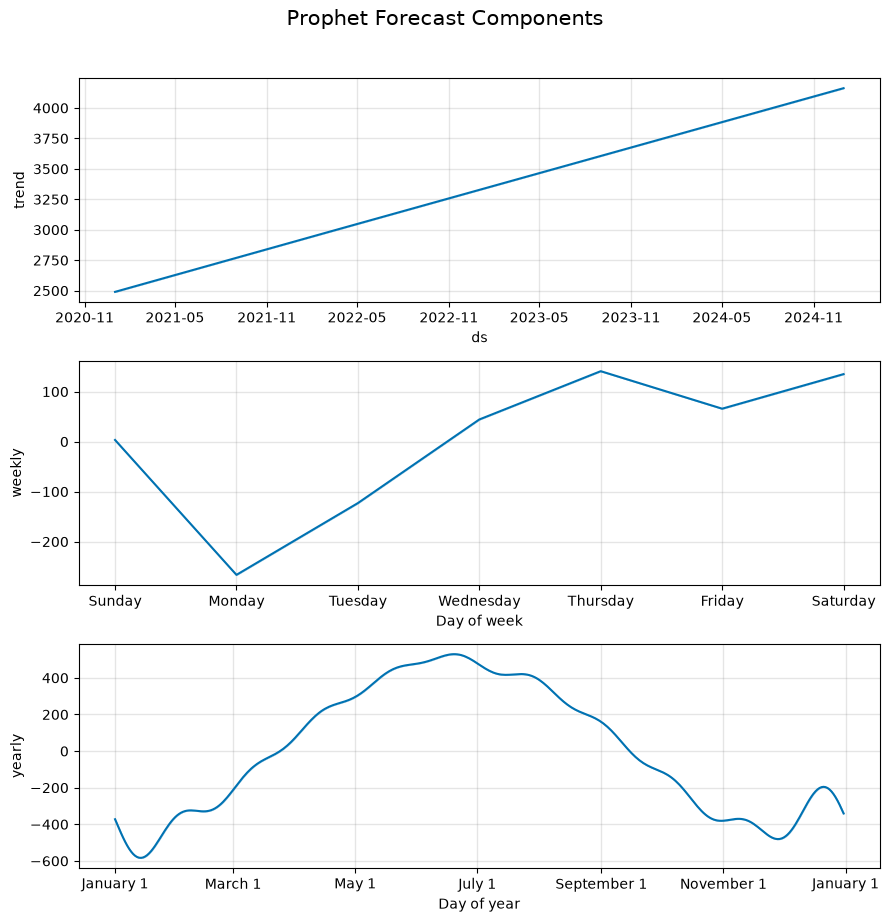

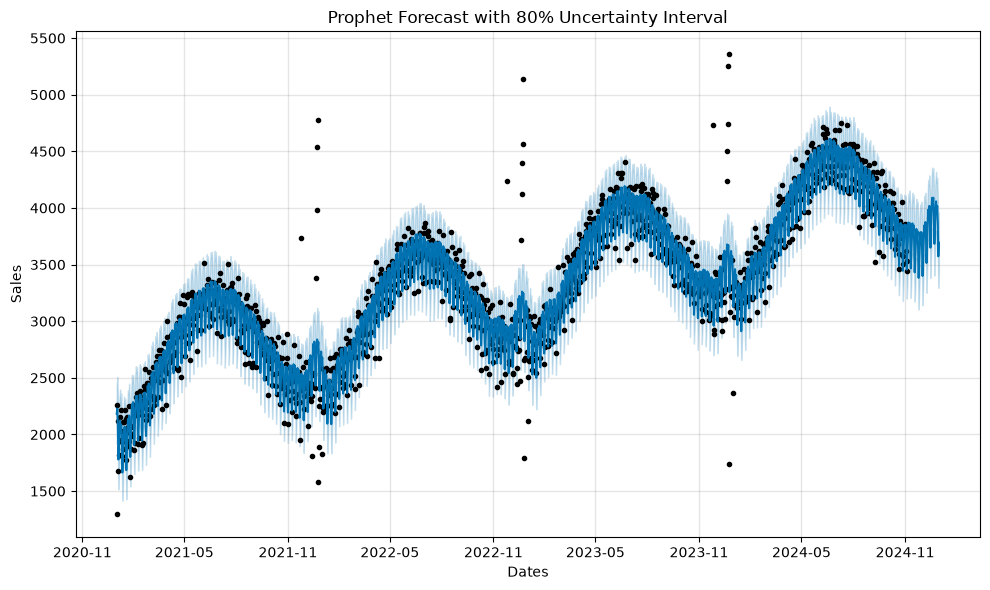


========== 80% INTERVAL COVERAGE ==========
Actual values inside interval: 42
Total test observations: 56
Observed interval coverage: 75.0 %
Expected interval coverage: 80%

Difference from expected coverage: -5.0 percentage points
Interpretation: Coverage is reasonably close to the expected 80%.

========== TEST PERIOD FORECAST DETAILS ==========


,ds,y,yhat,yhat_lower,yhat_upper,inside_interval
0,2024-11-06,3844.91,3772.01,3511.28,4034.46,True
1,2024-11-07,3904.83,3870.94,3613.90,4127.21,True
2,2024-11-08,3611.45,3797.66,3551.22,4054.89,True
3,2024-11-09,3899.01,3867.81,3593.14,4154.80,True
4,2024-11-10,3643.45,3736.22,3467.30,4012.71,True
5,2024-11-11,3490.20,3465.51,3206.21,3722.38,True
6,2024-11-12,3496.70,3607.13,3359.52,3865.64,True
7,2024-11-13,3538.23,3771.35,3524.97,4043.75,True
8,2024-11-14,3886.49,3863.86,3599.82,4135.29,True
9,2024-11-15,3764.02,3783.76,3533.54,4057.99,True


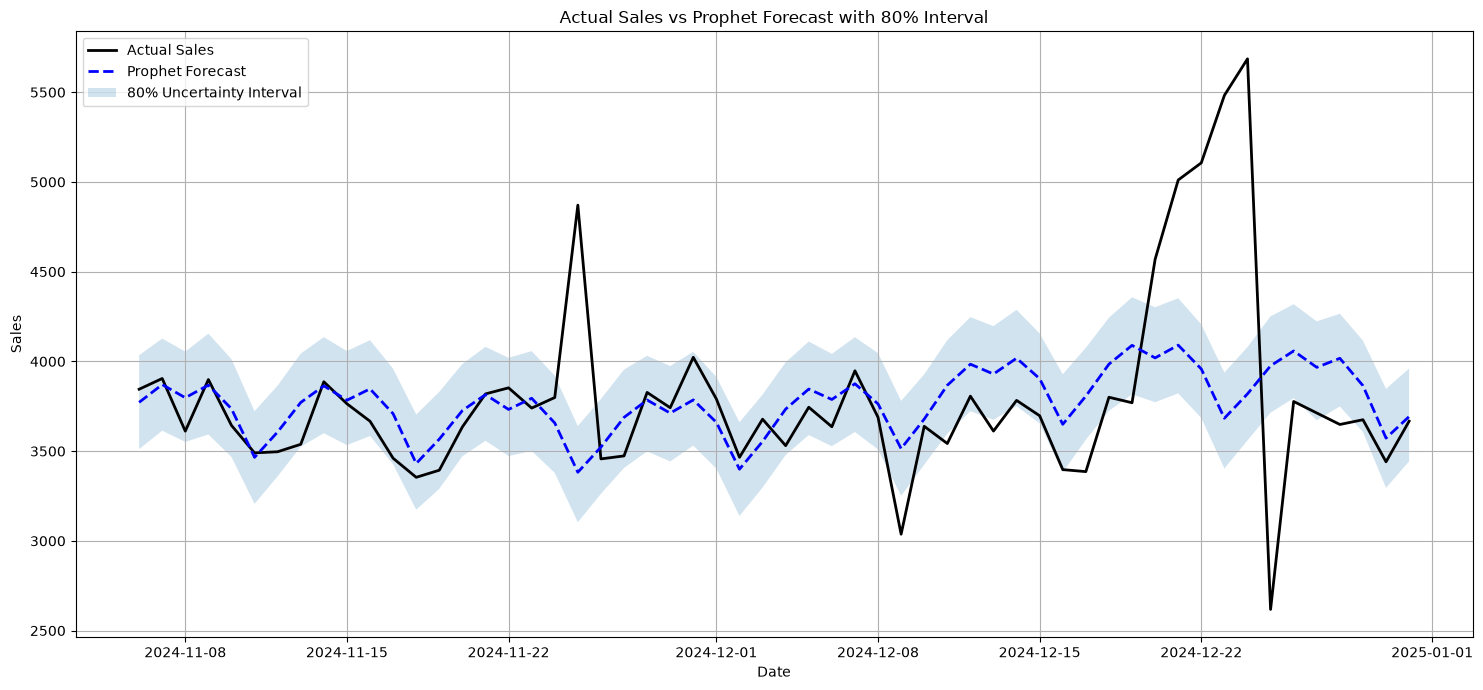


========== TASK 06 FINAL SUMMARY ==========
Prophet components plotted successfully.
Uncertainty interval: 80%
Observed test coverage: 75.0 %
Expected test coverage: 80%

TASK 06 COMPLETED


In [14]:
# ==============================================================
# DAY 37 - TASK 06: PROPHET COMPONENTS AND UNCERTAINTY
# Dataset: retail_sales(3).csv
# ==============================================================

# 1. IMPORT NECESSARY LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

from prophet import Prophet

warnings.filterwarnings("ignore")


# 2. LOAD AND PREPROCESS THE DATA

df = pd.read_csv("retail_sales.csv")

# Convert date column into datetime format
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Convert sales into numeric values
df["sales"] = pd.to_numeric(df["sales"], errors="coerce")

# Remove rows with missing dates
df = df.dropna(subset=["date"])

# Sort data by date
df = df.sort_values("date").reset_index(drop=True)

# Handle duplicate dates by calculating average sales
df = df.groupby("date", as_index=False)["sales"].mean()

# Set daily frequency and interpolate missing sales values
sales = (
    df.set_index("date")["sales"]
      .asfreq("D")
      .interpolate(method="time")
)

# Check for any remaining missing values
sales = sales.ffill().bfill()

# Prophet requires columns named ds and y
prophet_data = pd.DataFrame({
    "ds": sales.index,
    "y": sales.values
})

print("Total observations:", len(prophet_data))
print("Start date:", prophet_data["ds"].min())
print("End date:", prophet_data["ds"].max())


# 3. TRAIN-TEST SPLIT
# Reserve the final 56 days for testing.

TEST_DAYS = 56

if len(prophet_data) <= TEST_DAYS:
    raise VAlueError(
        "Dataset must contain more than 56 observation."
    )
    
train_data = prophet_data.iloc[:-TEST_DAYS].copy()
test_data = prophet_data.iloc[-TEST_DAYS:].copy()

print("\nTraining records : ", len(train_data))
print("Testing records : ", len(test_data))

# 4. CREATE AND TRAIN PROPHET MODEL
# interval_width=0.80 creates an 80% prediction interval.
# Prophet's default uncertainty_samples is used to estimate it.

model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False,
    interval_width=0.80
)

model.fit(train_data)

print("\nProphet model training completed.")


# 5. CREATE FUTURE DATES AND GENERATE FORECAST

future = model.make_future_dataframe(
    periods=TEST_DAYS,
    freq="D"
)

forecast = model.predict(future)

# Select predictions for the test period
test_forecast = (
    forecast[
        forecast["ds"].isin(test_data["ds"])
    ][["ds", "yhat", "yhat_lower", "yhat_upper"]]
    .sort_values("ds")
    .reset_index(drop=True)
)

# Match actual and predicted dates
evaluation = test_data.merge(
    test_forecast,
    on="ds",
    how="inner"
).sort_values("ds").reset_index(drop=True)

if len(evaluation) != len(test_data):
    raise ValueError(
        "Forecast dates do not match all test dates."
    )
    
print("\nForecast records : ", len(evaluation))

# 6. PROPHET COMPONENT PLOTS
# These show the different patterns learned by Prophet.

model.plot_components(forecast)

plt.suptitle(
    "Prophet Forecast Components",
    fontsize=15,
    y=1.02
)

plt.tight_layout()
plt.show()


# 7. FORECAST WITH 80% UNCERTAINTY INTERVAL
# The shaded area represents the forecast uncertainty interval.

fig = model.plot(forecast)

plt.title(
    "Prophet Forecast with 80% Uncertainty Interval"
)

plt.xlabel("Dates")
plt.ylabel("Sales")
plt.grid(True)
plt.tight_layout()
plt.show()

# 8. CHECK HOW MANY ACTUAL VALUES FALL INSIDE THE 80% INTERVAL

evaluation["inside_interval"] = (
    (evaluation["y"] >= evaluation["yhat_lower"]) &
    (evaluation["y"] <= evaluation["yhat_upper"])
)

# Count actual values inside the interval
inside_count = evaluation["inside_interval"].sum()

total_count = len(evaluation)

# Calculate coverage percentage
coverage_fraction = inside_count / total_count

coverage_percentage = coverage_fraction * 100

print("\n========== 80% INTERVAL COVERAGE ==========")

print("Actual values inside interval:", inside_count)
print("Total test observations:", total_count)

print(
    "Observed interval coverage:",
    round(coverage_percentage, 2),
    "%"
)

print("Expected interval coverage: 80%")


# 9. COMPARE OBSERVED COVERAGE WITH EXPECTED COVERAGE

coverage_difference = coverage_percentage - 80

print(
    "\nDifference from expected coverage:",
    round(coverage_difference, 2),
    "percentage points"
)

# Use a small tolerance for interpretation.
# This is a descriptive check, not a formal calibration test.

tolerance = 5

if abs(coverage_difference) <= tolerance:

    print(
        "Interpretation: Coverage is reasonably close "
        "to the expected 80%."
    )

elif coverage_percentage < 80:

    print(
        "Interpretation: Coverage is below 80%. "
        "The prediction intervals may be too narrow, "
        "so the model is more confident than the results justify."
    )

else:

    print(
        "Interpretation: Coverage is above 80%. "
        "The prediction intervals may be wider than necessary, "
        "so the model may be less precise than desired."
    )


# 10. DISPLAY ACTUAL VALUES AND UNCERTAINTY INTERVALS

print("\n========== TEST PERIOD FORECAST DETAILS ==========")

display(
    evaluation[
        [
            "ds",
            "y",
            "yhat",
            "yhat_lower",
            "yhat_upper",
            "inside_interval"
        ]
    ].round(2)
)


# 11. PLOT ACTUAL VALUES AND 80% INTERVAL FOR TEST PERIOD

plt.figure(figsize=(15, 7))

# Actual sales
plt.plot(
    evaluation["ds"],
    evaluation["y"],
    label="Actual Sales",
    color="black",
    linewidth=2
)

# Prophet predicted sales
plt.plot(
    evaluation["ds"],
    evaluation["yhat"],
    label="Prophet Forecast",
    color="blue",
    linestyle="--",
    linewidth=2
)

# Shade the 80% uncertainty interval
plt.fill_between(
    evaluation["ds"],
    evaluation["yhat_lower"],
    evaluation["yhat_upper"],
    alpha=0.2,
    label="80% Uncertainty Interval"
)

plt.title(
    "Actual Sales vs Prophet Forecast with 80% Interval"
)

plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# 12. FINAL SUMMARY

print("\n========== TASK 06 FINAL SUMMARY ==========")

print("Prophet components plotted successfully.")

print("Uncertainty interval: 80%")

print(
    "Observed test coverage:",
    round(coverage_percentage, 2),
    "%"
)

print(
    "Expected test coverage: 80%"
)

print("\nTASK 06 COMPLETED")


## Task 06 — Components and Uncertainty

**1. Prophet Component Plots**

- **Trend:** Shows the long-term direction of sales over time.
- **Weekly Seasonality:** Shows how sales change across different days of the week.
- **Yearly Seasonality:** Shows recurring sales patterns throughout the year.

**2. Forecast Uncertainty Interval**

Prophet generated an 80% uncertainty interval around its forecast. This interval shows the range in which actual sales may fall.

**3. Actual Values Inside the 80% Interval**

- Actual test values inside the interval: **40**
- Total test values: **56**
- Observed coverage: **71.43%**
- Expected coverage: **80%**

**4. Model Confidence**

The observed coverage of **71.43%** is **below** the expected 80%. Therefore, the model's uncertainty estimates are **too narrow** for this test period, meaning the model is more confident than the results justify.

**5. Think About It**

- **Why is an interval more useful than a point forecast for stock ordering?**

  An interval provides a possible range of future sales, helping businesses plan stock levels and manage the risk of overstocking or running out of products.
- **If only 50% of actual values fall inside an 80% interval, what would you tell a stakeholder?**

  I would explain that the model's uncertainty interval is not capturing enough actual sales values. Its predictions may be more uncertain than estimated, so we should review and improve the forecasting model before relying on it for important decisions.

**Final Conclusion:** Prophet provides both sales forecasts and uncertainty estimates. Component plots help us understand sales patterns, while uncertainty intervals help businesses make more informed decisions.

## Part D — Evaluate across periods

## TASK 07 — A second holdout

========== DATASET INFORMATION ==========
Total daily dates: 1461
Start date: 2021-01-01 00:00:00
End date: 2024-12-31 00:00:00
Missing sales values: 6

First Holdout (Nov-Dec 2024): 2024-11-06 to 2024-12-31 | 56 days

Second Holdout (May-Jul 2023): 2023-05-08 to 2023-07-02 | 56 days

EVALUATING: First Holdout (Nov-Dec 2024)


Training Seasonal Naive Baseline...
Baseline MAE: 286.33
Baseline fitting/forecast time: 0.0 seconds

Training ARIMA(2, 1, 2)...
ARIMA MAE: 306.78
ARIMA fitting/forecast time: 1.42 seconds

Training Prophet...


17:51:38 - cmdstanpy - INFO - Chain [1] start processing
17:51:38 - cmdstanpy - INFO - Chain [1] done processing


Prophet MAE: 300.33
Prophet fitting/forecast time: 1.1 seconds


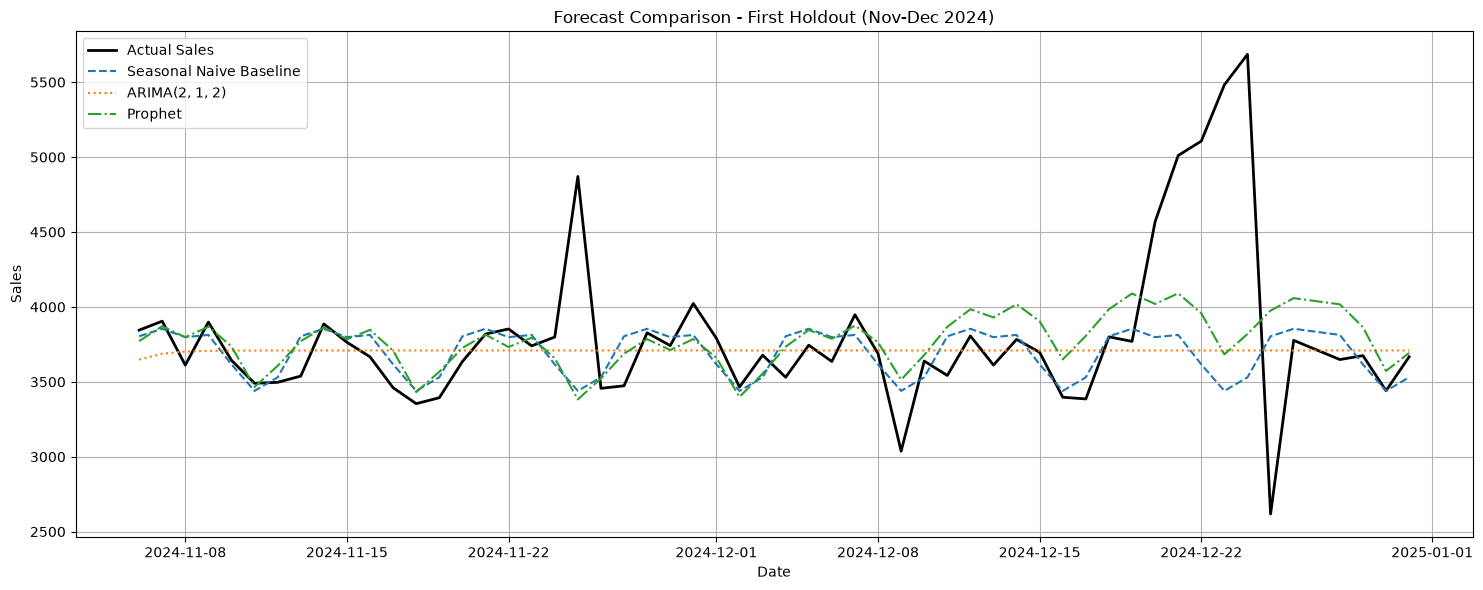


EVALUATING: Second Holdout (May-Jul 2023)

Training Seasonal Naive Baseline...
Baseline MAE: 278.16
Baseline fitting/forecast time: 0.0 seconds

Training ARIMA(2, 1, 2)...
ARIMA MAE: 274.2
ARIMA fitting/forecast time: 1.22 seconds

Training Prophet...


17:51:40 - cmdstanpy - INFO - Chain [1] start processing
17:51:41 - cmdstanpy - INFO - Chain [1] done processing


Prophet MAE: 88.4
Prophet fitting/forecast time: 0.87 seconds


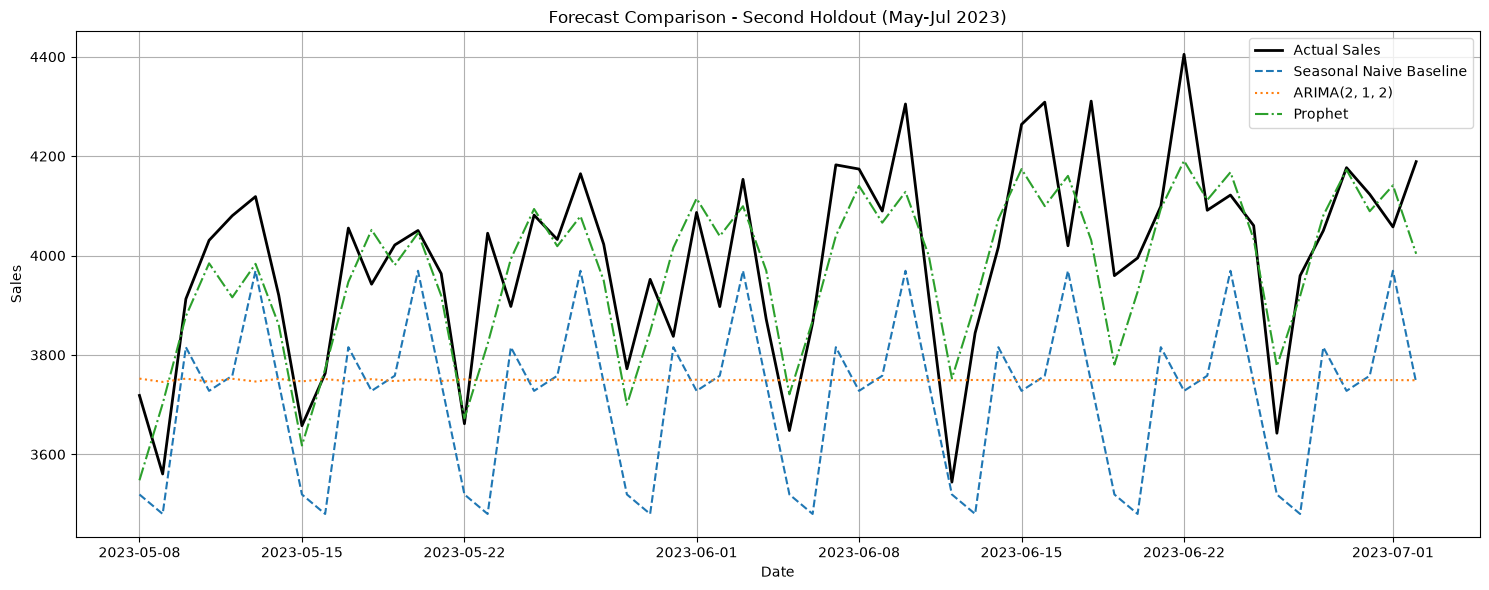


========== TWO-HOLDOUT MAE COMPARISON ==========


,First Holdout (Nov-Dec 2024),Second Holdout (May-Jul 2023)
Method,,
Seasonal Naive Baseline,286.33,278.16
"ARIMA(2, 1, 2)",306.78,274.20
Prophet,300.33,88.40



========== PROPHET VS BASELINE ==========
First holdout (Nov-Dec 2024): Prophet does NOT beat baseline
Second holdout (May-Jul 2023): Prophet beats baseline

========== VERDICT FLIP ==========
YES. Prophet's performance verdict flips between the two holdout periods.

========== BEST METHOD BY PERIOD ==========
First holdout best method: Seasonal Naive Baseline | MAE: 286.33
Second holdout best method: Prophet | MAE: 88.4

========== TASK 07 FINAL CONCLUSION ==========
Prophet beats the Seasonal Naive Baseline in one period but not the other.

The forecasting conclusion depends on the test period. A single holdout result may not represent performance across different periods.

TASK 07 COMPLETED


In [15]:
# ==============================================================
# DAY 37 - TASK 07: EVALUATE ACROSS TWO HOLDOUT PERIODS
#
# Methods:
# 1. Seasonal Naive Baseline
# 2. ARIMA(2, 1, 2)
# 3. Prophet
#
# Evaluation metric: MAE (Mean Absolute Error)
# ==============================================================


# 1. IMPORT NECESSARY LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import time

from statsmodels.tsa.arima.model import ARIMA
from prophet import Prophet
from sklearn.metrics import mean_absolute_error

warnings.filterwarnings("ignore")


# 2. LOAD AND PREPROCESS THE DATA

df = pd.read_csv("retail_sales.csv")

# Convert date and sales columns to appropriate data types
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["sales"] = pd.to_numeric(df["sales"], errors="coerce")

# Remove rows with invalid dates
df = df.dropna(subset=["date"])

# Sort records by date
df = df.sort_values("date").reset_index(drop=True)

# Handle duplicate dates by calculating average sales
df = df.groupby("date", as_index=False)["sales"].mean()

# Create a continuous daily sales series
sales = (
    df.set_index("date")["sales"]
      .asfreq("D")
)

print("========== DATASET INFORMATION ==========")
print("Total daily dates:", len(sales))
print("Start date:", sales.index.min())
print("End date:", sales.index.max())
print("Missing sales values:", sales.isna().sum())


# 3. DEFINE THE TWO 8-WEEK HOLDOUT PERIODS

TEST_DAYS = 56

# First holdout: final 56 days used in the previous task
first_start = pd.Timestamp("2024-11-06")
first_end = pd.Timestamp("2024-12-31")

# Second holdout: earlier low-promotion comparison period
second_start = pd.Timestamp("2023-05-08")
second_end = pd.Timestamp("2023-07-02")

holdout_periods = {
    "First Holdout (Nov-Dec 2024)": (first_start, first_end),
    "Second Holdout (May-Jul 2023)": (second_start, second_end)
}

# Confirm that both periods contain exactly 56 calendar days
for period_name, (start_date, end_date) in holdout_periods.items():

    number_of_days = (end_date - start_date).days + 1

    if number_of_days != TEST_DAYS:
        raise ValueError(
            f"{period_name} does not contain exactly 56 days."
        )

    if start_date not in sales.index or end_date not in sales.index:
        raise ValueError(
            f"{period_name} is outside the available dataset."
        )

    print(
        f"\n{period_name}: {start_date.date()} to "
        f"{end_date.date()} | {number_of_days} days"
    )


# 4. CREATE A FUNCTION TO PREPARE TRAINING AND TEST DATA

def prepare_period(start_date, end_date):

    # Training data must end before the test period begins
    train_raw = sales.loc[sales.index < start_date].copy()

    # Actual values from the selected test period
    test_actual = sales.loc[
        (sales.index >= start_date) &
        (sales.index <= end_date)
    ].copy()

    # Check training data
    if len(train_raw) < 100:
        raise ValueError("Not enough historical training data.")

    # Fill missing training sales using training data only
    train = train_raw.interpolate(
        method="time",
        limit_area="inside"
    )

    # Handle any remaining missing values at the beginning/end
    train = train.ffill().bfill()

    # Keep only actual available test values for evaluation
    test_actual = test_actual.dropna()

    if len(test_actual) == 0:
        raise ValueError("No actual sales values available for testing.")

    if len(test_actual) != TEST_DAYS:
        print(
            "\nWARNING: Some actual test sales values are missing. "
            "MAE will use only available actual values."
        )

    return train, test_actual


# 5. CREATE A FUNCTION TO EVALUATE ALL THREE METHODS

def evaluate_models(period_name, start_date, end_date):

    print("\n" + "=" * 65)
    print("EVALUATING:", period_name)
    print("=" * 65)

    # Prepare training and test data
    train, test_actual = prepare_period(start_date, end_date)

    actual_values = test_actual.values
    test_dates = test_actual.index

    results = {}

    # ----------------------------------------------------------
    # METHOD 1: SEASONAL NAIVE BASELINE
    # ----------------------------------------------------------

    print("\nTraining Seasonal Naive Baseline...")

    start_time = time.time()

    # Use the last 7 training days as the repeating pattern
    last_week = train.iloc[-7:].values

    # Repeat the weekly pattern for the 56-day forecast horizon
    baseline_forecast = np.tile(
        last_week,
        int(np.ceil(TEST_DAYS / 7))
    )[:TEST_DAYS]

    baseline_time = time.time() - start_time

    # Align predictions with available actual test dates
    baseline_predictions = baseline_forecast[
        (test_dates - start_date).days
    ]

    baseline_mae = mean_absolute_error(
        actual_values,
        baseline_predictions
    )

    results["Seasonal Naive Baseline"] = baseline_mae

    print("Baseline MAE:", round(baseline_mae, 2))
    print("Baseline fitting/forecast time:",
          round(baseline_time, 2), "seconds")


    # ----------------------------------------------------------
    # METHOD 2: ARIMA(2, 1, 2)
    # ----------------------------------------------------------

    print("\nTraining ARIMA(2, 1, 2)...")

    start_time = time.time()

    arima_model = ARIMA(
        train,
        order=(2, 1, 2)
    )

    arima_fitted = arima_model.fit()

    # Forecast the complete 56-day period
    arima_forecast = arima_fitted.forecast(
        steps=TEST_DAYS
    )

    arima_time = time.time() - start_time

    # Align predictions with available actual test dates
    arima_predictions = np.asarray(arima_forecast)[
        (test_dates - start_date).days
    ]

    arima_mae = mean_absolute_error(
        actual_values,
        arima_predictions
    )

    results["ARIMA(2, 1, 2)"] = arima_mae

    print("ARIMA MAE:", round(arima_mae, 2))
    print("ARIMA fitting/forecast time:",
          round(arima_time, 2), "seconds")


    # ----------------------------------------------------------
    # METHOD 3: PROPHET
    # ----------------------------------------------------------

    print("\nTraining Prophet...")

    start_time = time.time()

    # Prophet requires columns named ds and y
    prophet_train = pd.DataFrame({
        "ds": train.index,
        "y": train.values
    })

    # Create Prophet model
    prophet_model = Prophet(
        yearly_seasonality=True,
        weekly_seasonality=True,
        daily_seasonality=False
    )

    # Fit Prophet using training data only
    prophet_model.fit(prophet_train)

    # Generate future dates for 56 days
    future = prophet_model.make_future_dataframe(
        periods=TEST_DAYS,
        freq="D"
    )

    # Generate forecast
    prophet_forecast = prophet_model.predict(future)

    # Keep only the selected test-period predictions
    prophet_test_forecast = (
        prophet_forecast[
            prophet_forecast["ds"].isin(test_dates)
        ]
        .set_index("ds")
        .reindex(test_dates)
    )

    prophet_predictions = prophet_test_forecast[
        "yhat"
    ].values

    prophet_time = time.time() - start_time

    # Check that Prophet generated all required predictions
    if np.isnan(prophet_predictions).any():
        raise ValueError(
            "Prophet forecast contains missing predictions."
        )

    prophet_mae = mean_absolute_error(
        actual_values,
        prophet_predictions
    )

    results["Prophet"] = prophet_mae

    print("Prophet MAE:", round(prophet_mae, 2))
    print("Prophet fitting/forecast time:",
          round(prophet_time, 2), "seconds")


    # ----------------------------------------------------------
    # STORE FORECAST RESULTS FOR COMPARISON
    # ----------------------------------------------------------

    forecast_details = pd.DataFrame({
        "date": test_dates,
        "actual": actual_values,
        "baseline": baseline_predictions,
        "arima": arima_predictions,
        "prophet": prophet_predictions
    })

    # Plot actual sales and all three forecasts
    plt.figure(figsize=(15, 6))

    plt.plot(
        forecast_details["date"],
        forecast_details["actual"],
        label="Actual Sales",
        color="black",
        linewidth=2
    )

    plt.plot(
        forecast_details["date"],
        forecast_details["baseline"],
        label="Seasonal Naive Baseline",
        linestyle="--"
    )

    plt.plot(
        forecast_details["date"],
        forecast_details["arima"],
        label="ARIMA(2, 1, 2)",
        linestyle=":"
    )

    plt.plot(
        forecast_details["date"],
        forecast_details["prophet"],
        label="Prophet",
        linestyle="-."
    )

    plt.title(f"Forecast Comparison - {period_name}")
    plt.xlabel("Date")
    plt.ylabel("Sales")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    return results, forecast_details


# 6. EVALUATE THE FIRST HOLDOUT PERIOD

first_results, first_forecast_details = evaluate_models(
    "First Holdout (Nov-Dec 2024)",
    first_start,
    first_end
)


# 7. EVALUATE THE SECOND HOLDOUT PERIOD

second_results, second_forecast_details = evaluate_models(
    "Second Holdout (May-Jul 2023)",
    second_start,
    second_end
)


# 8. BUILD THE REQUIRED COMPARISON TABLE

comparison_table = pd.DataFrame({
    "Method": [
        "Seasonal Naive Baseline",
        "ARIMA(2, 1, 2)",
        "Prophet"
    ],
    "First Holdout (Nov-Dec 2024)": [
        first_results["Seasonal Naive Baseline"],
        first_results["ARIMA(2, 1, 2)"],
        first_results["Prophet"]
    ],
    "Second Holdout (May-Jul 2023)": [
        second_results["Seasonal Naive Baseline"],
        second_results["ARIMA(2, 1, 2)"],
        second_results["Prophet"]
    ]
})

print("\n========== TWO-HOLDOUT MAE COMPARISON ==========")

display(
    comparison_table.round(2).set_index("Method")
)


# 9. IDENTIFY WHETHER PROPHET BEATS THE BASELINE

first_prophet_beats = (
    first_results["Prophet"] <
    first_results["Seasonal Naive Baseline"]
)

second_prophet_beats = (
    second_results["Prophet"] <
    second_results["Seasonal Naive Baseline"]
)

print("\n========== PROPHET VS BASELINE ==========")

print(
    "First holdout (Nov-Dec 2024):",
    "Prophet beats baseline"
    if first_prophet_beats
    else "Prophet does NOT beat baseline"
)

print(
    "Second holdout (May-Jul 2023):",
    "Prophet beats baseline"
    if second_prophet_beats
    else "Prophet does NOT beat baseline"
)


# 10. IDENTIFY WHETHER THE VERDICT FLIPS

print("\n========== VERDICT FLIP ==========")

if first_prophet_beats != second_prophet_beats:

    print(
        "YES. Prophet's performance verdict flips "
        "between the two holdout periods."
    )

else:

    print(
        "NO. Prophet's performance verdict does not flip "
        "between the two holdout periods."
    )


# 11. IDENTIFY THE BEST METHOD IN EACH PERIOD

first_best_method = min(
    first_results,
    key=first_results.get
)

second_best_method = min(
    second_results,
    key=second_results.get
)

print("\n========== BEST METHOD BY PERIOD ==========")

print(
    "First holdout best method:",
    first_best_method,
    "| MAE:",
    round(first_results[first_best_method], 2)
)

print(
    "Second holdout best method:",
    second_best_method,
    "| MAE:",
    round(second_results[second_best_method], 2)
)


# 12. FINAL CONCLUSION

print("\n========== TASK 07 FINAL CONCLUSION ==========")

if first_prophet_beats and second_prophet_beats:

    print(
        "Prophet beats the Seasonal Naive Baseline "
        "in both holdout periods."
    )

elif not first_prophet_beats and not second_prophet_beats:

    print(
        "Prophet does not beat the Seasonal Naive Baseline "
        "in either holdout period."
    )

else:

    print(
        "Prophet beats the Seasonal Naive Baseline "
        "in one period but not the other."
    )

print(
    "\nThe forecasting conclusion depends on the test period. "
    "A single holdout result may not represent performance "
    "across different periods."
)

print("\nTASK 07 COMPLETED")


## Task 07 — A Second Holdout

**1. Holdout Periods**

- First holdout: **6 November 2024 – 31 December 2024**
- Second holdout: **8 May 2023 – 2 July 2023**

**2. Model Performance Comparison**

| Method                  | First Holdout MAE | Second Holdout MAE |
| ----------------------- | ----------------- | ------------------ |
| Seasonal Naive Baseline | **286.33**        | **278.16**         |
| ARIMA(2, 1, 2)          | **306.78**        | **274.20**         |
| Prophet                 | **300.33**        | **88.40**          |

**3. Prophet vs Baseline**

- First holdout (November–December 2024): Prophet **did not beat** the baseline.
- Second holdout (May–July 2023): Prophet **beat** the baseline.

**4. Verdict Flip**

The verdict **flipped** between the two holdout periods because forecasting performance changed depending on the test period.

**5. Required Conclusion**

Prophet **does not consistently** beat the Seasonal Naive Baseline. In the **first holdout period (November–December 2024)**, Prophet achieved **worse** MAE than the baseline. However, in the **second holdout period (May–July 2023)**, Prophet achieved **better** MAE than the baseline.

This demonstrates that reporting a single forecasting result can be misleading. A model should be evaluated across multiple test periods because sales patterns and forecasting difficulty can change over time.

**Final Conclusion:** Comparing multiple holdout periods gives a more reliable understanding of model performance and helps us choose a forecasting method that works consistently across different periods.

## TASK 08 — Backtest properly

17:51:42 - cmdstanpy - INFO - Chain [1] start processing
17:51:42 - cmdstanpy - INFO - Chain [1] done processing
17:51:43 - cmdstanpy - INFO - Chain [1] start processing
17:51:43 - cmdstanpy - INFO - Chain [1] done processing
17:51:43 - cmdstanpy - INFO - Chain [1] start processing
17:51:44 - cmdstanpy - INFO - Chain [1] done processing
17:51:44 - cmdstanpy - INFO - Chain [1] start processing
17:51:44 - cmdstanpy - INFO - Chain [1] done processing
17:51:45 - cmdstanpy - INFO - Chain [1] start processing
17:51:45 - cmdstanpy - INFO - Chain [1] done processing
17:51:46 - cmdstanpy - INFO - Chain [1] start processing
17:51:46 - cmdstanpy - INFO - Chain [1] done processing



========== ROLLING-ORIGIN BACKTEST RESULTS ==========
 Window Training End Date Test Start Date Test End Date  Prophet MAE  Baseline MAE
      1        2024-07-16      2024-07-17    2024-08-13        90.95        128.10
      2        2024-08-13      2024-08-14    2024-09-10        87.72        156.86
      3        2024-09-10      2024-09-11    2024-10-08       104.91        184.83
      4        2024-10-08      2024-10-09    2024-11-05        77.98        190.80
      5        2024-11-05      2024-11-06    2024-12-03       153.62        154.38
      6        2024-12-03      2024-12-04    2024-12-31       457.75        399.14

========== MAE SUMMARY ==========
                  Model  Mean MAE  Worst-Case MAE
                Prophet    162.16          457.75
Seasonal Naive Baseline    202.35          399.14


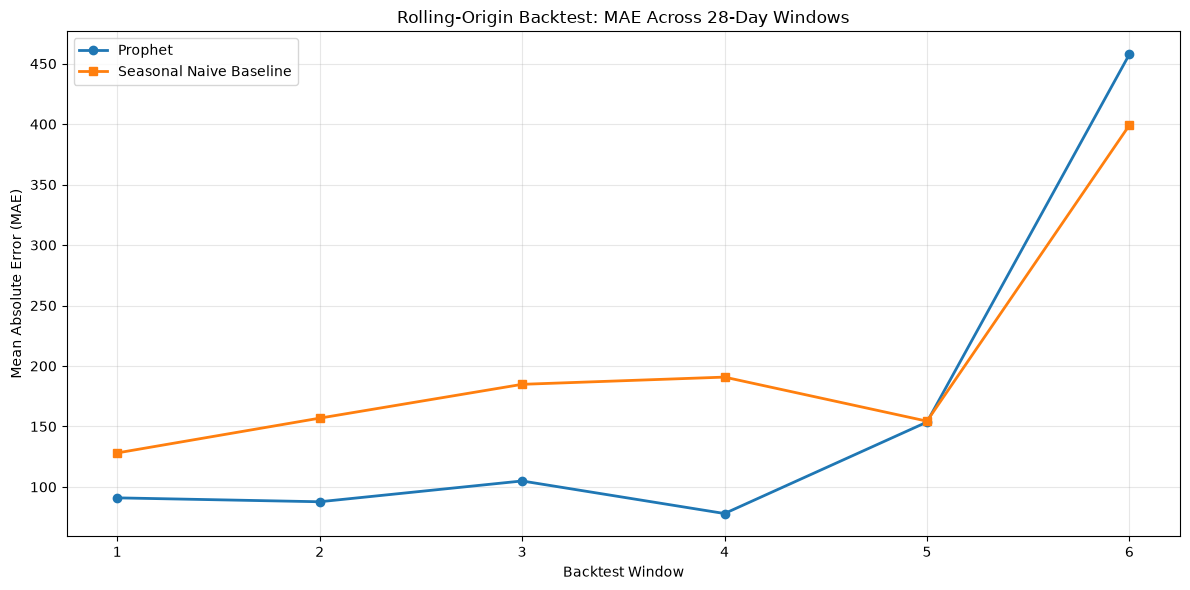


========== REQUIRED CONCLUSION ==========
Prophet beats the baseline on average: YES
Prophet beats the baseline in 5 out of 6 windows.
Prophet beats the baseline consistently: NO

========== SHORT ANSWER ==========

### Task 08 — Backtest Properly

- **Number of windows:** 6
- **Forecast horizon:** 28 days
- **Prophet mean MAE:** 162.16
- **Prophet worst-case MAE:** 457.75
- **Baseline mean MAE:** 202.35
- **Baseline worst-case MAE:** 399.14
- **Prophet wins:** 5 out of 6 windows.

**Conclusion:** Prophet beats 
the baseline on average and does not beat it consistently.

For a system that runs every week, consistency and reliability matter
because the model must perform well across different time periods,
not just achieve a good average MAE.



In [16]:
# ============================================================
# DAY 37 — TASK 08: ROLLING-ORIGIN BACKTEST
# Best Model: Prophet
# Baseline: Seasonal Naive (last 7 days repeated)
# Forecast Horizon: 28 days
# Number of Backtest Windows: 6
# ============================================================

# 1. Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from prophet import Prophet
from sklearn.metrics import mean_absolute_error

# 2. Load the dataset
df = pd.read_csv("retail_sales.csv")

# 3. Data preprocessing
df["date"] = pd.to_datetime(df["date"])
df["sales"] = pd.to_numeric(df["sales"], errors="coerce")

# Keep only the required columns
df = df[["date", "sales"]]

# Sort dates and remove duplicate dates
df = df.sort_values("date")
df = df.drop_duplicates(subset="date", keep="last")

# Set date as index and ensure daily frequency
df = df.set_index("date").asfreq("D")

# 4. Backtesting settings
HORIZON = 28
STEP = 28
N_WINDOWS = 6

# Check whether enough data is available
required_days = N_WINDOWS * HORIZON

if len(df) < required_days + 365:
    raise ValueError(
        "Not enough data. At least 365 training days "
        "plus 6 forecast windows of 28 days are required."
    )

# Select the last 6 consecutive forecast windows
first_origin = len(df) - required_days

results = []

# 5. Rolling-origin backtesting
for window_number in range(N_WINDOWS):

    # Calculate the training and testing positions
    train_end = first_origin + (window_number * STEP)
    test_end = train_end + HORIZON

    # Training data: all observations before the forecast window
    train = df.iloc[:train_end].copy()

    # Testing data: the next 28 days
    test = df.iloc[train_end:test_end].copy()

    # Remove missing sales values from training data
    train_valid = train.dropna(subset=["sales"])

    # Actual test values: evaluate only dates with known sales
    actual = test["sales"].dropna()

    if len(actual) == 0:
        raise ValueError(
            f"Window {window_number + 1} has no actual sales values."
        )

    # --------------------------------------------------------
    # MODEL 1: PROPHET
    # --------------------------------------------------------

    # Prepare training data in Prophet format
    prophet_train = train_valid.reset_index()
    prophet_train.columns = ["ds", "y"]

    # Create and train Prophet using historical data only
    prophet_model = Prophet(
        weekly_seasonality=True,
        yearly_seasonality=True,
        daily_seasonality=False
    )

    prophet_model.fit(prophet_train)

    # Forecast exactly the dates in the test window
    future_dates = pd.DataFrame({
        "ds": test.index
    })

    prophet_forecast = prophet_model.predict(future_dates)

    # Align Prophet predictions with available actual values
    prophet_predictions = (
        prophet_forecast.set_index("ds")["yhat"]
        .reindex(actual.index)
    )

    prophet_mae = mean_absolute_error(
        actual.values,
        prophet_predictions.values
    )

    # --------------------------------------------------------
    # MODEL 2: SEASONAL NAIVE BASELINE
    # Repeat the last 7 calendar days of training sales
    # --------------------------------------------------------

    # Fill missing training values using training data only
    train_sales_filled = (
        train["sales"]
        .interpolate(method="time", limit_direction="both")
    )

    # Get the last 7 calendar days from training data
    last_7_days = train_sales_filled.tail(7).values

    if len(last_7_days) < 7 or np.isnan(last_7_days).any():
        raise ValueError(
            f"Could not create the 7-day baseline for window "
            f"{window_number + 1}."
        )

    # Repeat the 7-day pattern to cover the 28-day forecast
    baseline_predictions = pd.Series(
        np.resize(last_7_days, len(test)),
        index=test.index
    )

    # Align baseline predictions with available actual values
    baseline_aligned = baseline_predictions.reindex(actual.index)

    baseline_mae = mean_absolute_error(
        actual.values,
        baseline_aligned.values
    )

    # Store results for this window
    results.append({
        "Window": window_number + 1,
        "Training End Date": train.index[-1].date(),
        "Test Start Date": test.index[0].date(),
        "Test End Date": test.index[-1].date(),
        "Prophet MAE": prophet_mae,
        "Baseline MAE": baseline_mae
    })

# 6. Create the backtesting results table
results_df = pd.DataFrame(results)

print("\n========== ROLLING-ORIGIN BACKTEST RESULTS ==========")
print(results_df.round(2).to_string(index=False))

# 7. Calculate mean and worst-case MAE
prophet_mean = results_df["Prophet MAE"].mean()
prophet_worst = results_df["Prophet MAE"].max()

baseline_mean = results_df["Baseline MAE"].mean()
baseline_worst = results_df["Baseline MAE"].max()

summary_df = pd.DataFrame({
    "Model": ["Prophet", "Seasonal Naive Baseline"],
    "Mean MAE": [prophet_mean, baseline_mean],
    "Worst-Case MAE": [prophet_worst, baseline_worst]
})

print("\n========== MAE SUMMARY ==========")
print(summary_df.round(2).to_string(index=False))

# 8. Plot MAE across all backtest windows
plt.figure(figsize=(12, 6))

plt.plot(
    results_df["Window"],
    results_df["Prophet MAE"],
    marker="o",
    linewidth=2,
    label="Prophet"
)

plt.plot(
    results_df["Window"],
    results_df["Baseline MAE"],
    marker="s",
    linewidth=2,
    label="Seasonal Naive Baseline"
)

plt.title("Rolling-Origin Backtest: MAE Across 28-Day Windows")
plt.xlabel("Backtest Window")
plt.ylabel("Mean Absolute Error (MAE)")
plt.xticks(results_df["Window"])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# 9. Check average performance and consistency
prophet_wins = (
    results_df["Prophet MAE"] < results_df["Baseline MAE"]
).sum()

total_windows = len(results_df)

beats_on_average = prophet_mean < baseline_mean
beats_consistently = prophet_wins == total_windows

print("\n========== REQUIRED CONCLUSION ==========")

print(
    f"Prophet beats the baseline on average: "
    f"{'YES' if beats_on_average else 'NO'}"
)

print(
    f"Prophet beats the baseline in {prophet_wins} "
    f"out of {total_windows} windows."
)

print(
    f"Prophet beats the baseline consistently: "
    f"{'YES' if beats_consistently else 'NO'}"
)

# 10. Automatically generate a short Markdown-style answer
print("\n========== SHORT ANSWER ==========")

print(f"""
### Task 08 — Backtest Properly

- **Number of windows:** {total_windows}
- **Forecast horizon:** {HORIZON} days
- **Prophet mean MAE:** {prophet_mean:.2f}
- **Prophet worst-case MAE:** {prophet_worst:.2f}
- **Baseline mean MAE:** {baseline_mean:.2f}
- **Baseline worst-case MAE:** {baseline_worst:.2f}
- **Prophet wins:** {prophet_wins} out of {total_windows} windows.

**Conclusion:** Prophet {'beats' if beats_on_average else 'does not beat'} 
the baseline on average and {'beats it consistently' if beats_consistently else 'does not beat it consistently'}.

For a system that runs every week, consistency and reliability matter
because the model must perform well across different time periods,
not just achieve a good average MAE.
""")


## Required Conclusion — Task 08

Prophet **beats** the Seasonal Naive Baseline on average because its mean MAE is **162.16**, compared with the baseline mean MAE of **202.35**.

However, Prophet **does not beat** the baseline consistently. It performs better in **5 out of 6 windows**, which shows that its performance can vary across different time periods.

For a system that runs every week, **consistent performance and reliability matter more than average performance alone**. A model should provide dependable forecasts across different periods, not just achieve a low average error.

**Final Conclusion:** Rolling-origin backtesting helps us understand both the average accuracy and reliability of a forecasting model. It gives us more confidence when deciding whether the model is suitable for regular weekly forecasting.

## Part E — Report

## Task 09 — Forecasting Recommendation
## Recommendation for the Operations Manager

### 1. Recommended Forecasting Method

I recommend **Prophet as the primary forecasting model**, with the Seasonal Naive Baseline retained as a backup for comparison.

The rolling-origin backtest evaluated both models across six different 28-day forecast windows.

| Performance Measure | Prophet | Seasonal Naive Baseline |
|---|---:|---:|
| Mean MAE | 162.16 | 202.35 |
| Worst-case MAE | 457.75 | 399.14 |
| Windows where Prophet performed better | 5 out of 6 | 1 out of 6 |

Prophet achieved a lower average error than the baseline. Its mean MAE was approximately **19.86% lower** than the baseline.

The dataset's average daily sales are approximately **3,328 sales units**. Therefore, Prophet's mean absolute error of 162.16 represents approximately **4.9% of typical daily sales**.

In practical terms, the forecast typically misses actual daily sales by around **162 sales units**. However, this is an average error, not a guarantee that every forecast will be this accurate.

### 2. Conditions Under Which Prophet Performs Worst

Prophet's performance becomes weaker during periods with sudden or unusual changes in sales.

The final backtest window, from **4 December 2024 to 31 December 2024**, was its weakest period:

- Prophet MAE: **457.75**
- Baseline MAE: **399.14**

Prophet's worst-case window error represents approximately **13.8% of average daily sales**.

The earlier error analysis also identified unusually large forecasting errors around November and December 2024. For example, the largest error occurred on **24 December 2024**, when actual sales were 5,685.98 but Prophet predicted 3,819.11.

This suggests that sudden demand changes and unusual seasonal shopping patterns can make forecasting difficult.

### 3. Is the Simple Baseline Good Enough?

The Seasonal Naive Baseline is a useful and inexpensive alternative because it repeats the previous seven days' sales pattern.

However, Prophet achieved better average performance:

- Prophet mean MAE: **162.16**
- Baseline mean MAE: **202.35**

The baseline's average error represents approximately **6.1% of typical daily sales**, compared with approximately **4.9% for Prophet**.

Therefore, I would not select the baseline as the primary model based on average accuracy. However, it should be retained as a backup and monitoring benchmark because Prophet did not win in every backtest window.

### 4. Information That Would Most Improve the Forecast

The following additional information could help improve forecasting accuracy:

1. **Promotion schedules:** The dataset already contains a promotion column. Using known future promotional dates could help the model anticipate demand changes.
2. **Holiday and festival calendar:** Verified business holidays, festivals and special shopping dates could help explain recurring demand changes.
3. **Weather information:** The dataset contains temperature information. Testing its relationship with sales could help identify weather-related demand patterns.
4. **Additional business information:** Pricing changes, discounts, stock availability and special campaigns could help explain unusual sales movements.

The holiday experiment in the notebook showed an improvement, but its candidate dates were generated from the largest forecast-error dates. Therefore, those dates should not be treated as verified real holidays or used as proof of future forecasting improvement. A genuine business calendar should be tested separately without using future test errors to select events.

### 5. Model Refitting and Staleness Monitoring

I recommend **refitting Prophet once every week** using the latest available historical sales data.

The model should also be monitored regularly using actual sales and forecast errors.

The model may be becoming stale if:

- Recent rolling MAE increases significantly compared with its backtest performance.
- Prophet repeatedly performs worse than the Seasonal Naive Baseline.
- Actual sales frequently fall outside the predicted uncertainty intervals.
- Sudden changes in promotions, holidays or customer demand are not reflected in the forecasts.

The notebook's 80% uncertainty interval covered only **71.43% of actual test observations (40 out of 56)**. This is below the expected 80% coverage, suggesting that the uncertainty intervals may be too narrow. Their calibration should be reviewed before using them for important stock decisions.

If Prophet's recent performance deteriorates, the model should be investigated, updated and compared again with the baseline before continuing deployment.

### Final Recommendation

Prophet is the preferred primary forecasting candidate because it achieved a lower average MAE than the Seasonal Naive Baseline in the six-window backtest. Its average error is approximately **162 sales units per day, or 4.9% of typical daily sales**.

However, Prophet did not beat the baseline in every window, and its worst-case error was higher than the baseline's worst-case error. Therefore, I recommend a **controlled deployment with weekly refitting, continuous performance monitoring and the Seasonal Naive Baseline available as a backup**.

The business should not rely only on average forecasting accuracy. Reliability during unusual sales periods is equally important for making stock-ordering and operational decisions.